# Radiative cooling: experimental processing and Random Forest validation

This report implements the supplied project brief using the available Sample 2
instrument exports. It includes original measurements, acquisition checks, a
20-sample moving average, three-minute alignment, missing-interval exclusion,
an exported final dataset, and held-out Random Forest validation. All 20 figures
remain embedded in this notebook.

Read the [methodology](../docs/methodology.md) for the explicit adaptations from
`PLOT_TRESCO_CORRELATIONS_ML-2.m` and the [requirements audit](../docs/requirements.md).
The [final processed CSV](../processed/final_processed_dataset.csv) is the exact
physical-unit table used by the model. The five-slide presentation is outside scope.


## 1. Configuration and provenance

The primary analysis uses each instrument's own timestamps (April-May 2026).
The longer April-July merged table is retained for acquisition comparison and
explicit heat-flux unit metadata, not as the primary alignment source. Later native
instrument exports are unavailable, so no independently verified full-campaign
synchronization is claimed.

The MATLAB reference applies `movmean(...,20)` before resampling. We reproduce its
centered 20-observation window (10 previous, current, 9 following) and shrinking
endpoints, within uninterrupted valid segments only. The PDF's three-minute grid,
missing-interval exclusion, five environmental predictors, and basic Random Forest
take precedence over the older MATLAB five-minute interpolation and neural network.
The window is fixed from the reference, never selected by model scores.


In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import sklearn
from IPython.display import display, Markdown
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

def find_project_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (base, base / 'Dipu_Bhai_Thesis'):
            if (candidate / 'processed/merged_dataset_104957.csv').is_file():
                return candidate
    raise FileNotFoundError('Open this notebook from the project or its code folder.')

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / 'processed'
DATA_SCOPE = 'native_exports'  # Primary: independently available instrument timestamps
MOVING_WINDOW = 20
MAX_SOURCE_GAP = pd.Timedelta('3min')
GRID = '3min'
SEED = 42
VALIDATION_FRACTION = 0.20
CHRONOLOGICAL_GAP = pd.Timedelta('1D')
HEAT_FLUX_SENSITIVITY_V = 60e-6  # V per (W/m²), inherited, not independently certified
FEATURES = ['T_amb', 'RH', 'v', 'G', 'T_sky']
TARGET = 'Q_net'
MODEL_COLS = FEATURES + [TARGET]
PLOT_ORDER = [TARGET, 'G', 'T_amb', 'T_sky', 'RH', 'v']
LABELS = {
    'Q_net': ('Recorded net heat flux', 'Q_net [W/m²]', '#202020'),
    'G': ('Solar irradiance', 'G [W/m²]', '#dc8b12'),
    'T_amb': ('Ambient temperature', 'T_amb [°C]', '#2376b7'),
    'T_sky': ('Sky temperature', 'T_sky [°C]', '#c83d4b'),
    'RH': ('Relative humidity', 'RH [%]', '#329261'),
    'v': ('Wind speed', 'v [m/s]', '#8661b3'),
}
assert DATA_SCOPE == 'native_exports'
plt.rcParams.update({'figure.dpi': 105, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)
versions = pd.Series({'Python': platform.python_version(), 'pandas': pd.__version__,
                      'NumPy': np.__version__, 'Matplotlib': matplotlib.__version__,
                      'scikit-learn': sklearn.__version__}, name='Version')
display(versions.to_frame())
print(f'Scope: {DATA_SCOPE}; grid: {GRID}; random seed: {SEED}')


,Version
Python,3.11.3
pandas,2.1.4
NumPy,1.26.4
Matplotlib,3.10.5
scikit-learn,1.5.2


Scope: native_exports; grid: 3min; random seed: 42


## 2. Read and inspect the available acquisitions

In [2]:
source_names = {
    'RAFT export': 'merged_raft.csv',
    'Weather export': 'merged_meteo.csv',
    'Sky export': 'merged_ir.csv',
    'Full merged table': 'merged_dataset_104957.csv',
}
source_frames = {name: pd.read_csv(DATA_DIR / filename, low_memory=False)
                 for name, filename in source_names.items()}
raft = source_frames['RAFT export'].copy()
weather = source_frames['Weather export'].copy()
sky = source_frames['Sky export'].copy()
full = source_frames['Full merged table'].copy()
raft['timestamp'] = pd.to_datetime(raft['DATE'].str.strip() + ' ' + raft['TIME'].str.strip(),
                                  format='%d/%m/%Y %H:%M:%S', errors='raise')
# Remove the English weekday and map the English month explicitly (locale-independent).
month_numbers = dict(zip(['January', 'February', 'March', 'April', 'May', 'June',
                         'July', 'August', 'September', 'October', 'November', 'December'],
                        [f'{m:02}' for m in range(1, 13)]))
weather_time = weather['TIME'].str.extract(
    r'^\w+ (\d{1,2}) (\w+) (\d{4}) (\d{2}:\d{2}:\d{2})$')
weather['timestamp'] = pd.to_datetime(
    weather_time[2] + '-' + weather_time[1].map(month_numbers) + '-' +
    weather_time[0].str.zfill(2) + ' ' + weather_time[3], errors='raise')
sky['timestamp'] = pd.to_datetime(sky['TIMESTAMP'], format='mixed', errors='raise')
full['timestamp'] = pd.to_datetime(full['timestamp'], errors='raise')
for name, frame in [('RAFT', raft), ('Weather', weather), ('Sky', sky), ('Full', full)]:
    assert frame['timestamp'].notna().all(), f'{name}: missing/invalid timestamps'
assert not full['timestamp'].duplicated().any(), 'Full table has ambiguous duplicate timestamps.'

def numeric(series):
    return pd.to_numeric(series, errors='coerce').replace([np.inf, -np.inf], np.nan)

for column in MODEL_COLS + ['Q_net_raw', 'Q_net_voltage_V', 'T_pt100_C']:
    full[column] = numeric(full[column])
full = full.sort_values('timestamp').set_index('timestamp')
inventory = []
for name, frame in [('RAFT export', raft), ('Weather export', weather),
                    ('Sky export', sky), ('Full merged table', full.reset_index())]:
    times = frame['timestamp'].sort_values()
    steps = times.diff().dropna()
    inventory.append({'Source': name, 'Rows': len(frame), 'First': times.min(),
                      'Last': times.max(), 'Duplicate timestamps': int(times.duplicated().sum()),
                      'Median positive step (s)': steps[steps > pd.Timedelta(0)].dt.total_seconds().median(),
                      'SHA256': hashlib.sha256((DATA_DIR / source_names[name]).read_bytes()).hexdigest()})
source_inventory = pd.DataFrame(inventory).set_index('Source')
display(source_inventory.drop(columns='SHA256'))
display(source_inventory[['SHA256']])
display(sky.groupby('RECORD_TYPE').agg(rows=('TIMESTAMP', 'size'),
                                      first=('timestamp', 'min'), last=('timestamp', 'max')))

,Rows,First,Last,Duplicate timestamps,Median positive step (s)
Source,,,,,
RAFT export,35132,2026-04-17 14:53:44.000,2026-05-15 12:02:32,0,60.0
Weather export,35327,2026-04-17 14:54:24.000,2026-05-15 12:03:46,4,60.0
Sky export,33890,2026-04-20 09:36:08.788,2026-05-15 12:03:23,0,60.0
Full merged table,104957,2026-04-17 14:53:44.000,2026-07-03 07:59:16,0,60.0


,SHA256
Source,
RAFT export,6fb1a55e183d4c03a06c6427a776e7f6b55f84983bd85b...
Weather export,fc8057c64cc3b1396d8ea9f22598d4ce2dc96650314401...
Sky export,81a249802d48274a28b057c626f386853faa289a92cbc1...
Full merged table,abedc40fb470cb793e3590b4d1d6693f5010bd2ffaa9c2...


,rows,first,last
RECORD_TYPE,,,
DETAILED_DAT,9573,2026-04-20 09:36:08.788,2026-04-28 14:41:11.712
SIMPLE_TXT,24317,2026-04-28 14:46:26.000,2026-05-15 12:03:23.000


### Heat-flux units and duplicate timestamps

RAFT unit metadata are looked up at exact matching timestamps and checked against
the unchanged raw numbers. Sensitivity remains 60 microvolts per W/m². This proves
conversion consistency, not sensor calibration or polarity. The MATLAB sign reversal
belongs to a different experiment and is not imposed on these recordings.

As in MATLAB `unique(...,'stable')`, the first record at each duplicate timestamp is
retained. Sorting is stable. Duplicate and conflicting-value counts are reported.
Humidity remains percent and temperatures remain Celsius, with units explicit.


In [3]:
raft = raft.sort_values('timestamp', kind='stable').set_index('timestamp')
unit_lookup = full[['Q_raw_unit', 'Q_net_raw']].reindex(raft.index)
raft_raw = numeric(raft['HEAT_FLUX_V'])
assert np.allclose(raft_raw, unit_lookup['Q_net_raw'], equal_nan=True), (
    'RAFT raw values disagree with the exact-timestamp unit metadata source.')
unit_scale = unit_lookup['Q_raw_unit'].map({'V': 1.0, 'uV': 1e-6})
assert unit_scale[raft_raw.notna()].notna().all(), 'Unknown unit for a finite RAFT value.'
raft_voltage = raft_raw * unit_scale
raft_flux = raft_voltage / HEAT_FLUX_SENSITIVITY_V
known = full['Q_raw_unit'].map({'V': 1.0, 'uV': 1e-6})
assert known[full['Q_net_raw'].notna()].notna().all()
assert np.allclose(full['Q_net_raw'] * known, full['Q_net_voltage_V'], equal_nan=True)
assert np.allclose(full['Q_net_voltage_V'] / HEAT_FLUX_SENSITIVITY_V,
                   full[TARGET], equal_nan=True)
assert np.allclose(raft_flux, full[TARGET].reindex(raft.index), equal_nan=True)
display(pd.DataFrame({'Rows': full.groupby('Q_raw_unit', dropna=False).size()}))
print('Raw-to-voltage and voltage-to-flux arithmetic agree with the existing full table.')
print('The sign and calibration coefficient remain inherited measurement assumptions.')

weather = weather.sort_values('timestamp', kind='stable').set_index('timestamp')
sky = sky.sort_values('timestamp', kind='stable').set_index('timestamp')
assert sky['RECORD_TYPE'].isin(['SIMPLE_TXT', 'DETAILED_DAT']).all()
sky_temperature = numeric(sky['TEMPERATURE_C']).where(
    sky['RECORD_TYPE'].eq('SIMPLE_TXT'), numeric(sky['TPROC']))
native_series = {TARGET: raft_flux, 'T_sky': sky_temperature}
for original, name in {'TEMP': 'T_amb', 'RH': 'RH', 'SPEED': 'v', 'SOLARRAD': 'G'}.items():
    native_series[name] = numeric(weather[original])
duplicate_audit = pd.DataFrame([
    {'Variable': name, 'Duplicate records': int(series.index.duplicated().sum()),
     'Conflicting timestamps': int(series.groupby(level=0).nunique(dropna=False).gt(1).sum())}
    for name, series in native_series.items()]).set_index('Variable')
display(duplicate_audit)
native_series = {name: series.loc[~series.index.duplicated(keep='first')].sort_index().rename(name)
                 for name, series in native_series.items()}
native_full = pd.concat(native_series, axis=1).sort_index()[MODEL_COLS]
display(pd.DataFrame({name: {'readings': len(series), 'finite': int(series.notna().sum()),
                            'missing': int(series.isna().sum())}
                      for name, series in native_series.items()}).T)


,Rows
Q_raw_unit,
V,1488
missing,1
uV,103468


Raw-to-voltage and voltage-to-flux arithmetic agree with the existing full table.
The sign and calibration coefficient remain inherited measurement assumptions.


,Duplicate records,Conflicting timestamps
Variable,,
Q_net,0,0
T_sky,0,0
T_amb,4,3
RH,4,1
v,4,4
G,4,4


,readings,finite,missing
Q_net,35132,35131,1
T_sky,33890,33890,0
T_amb,35323,35323,0
RH,35323,35323,0
v,35323,35323,0
G,35323,35323,0


### Original-timestamp plots, before modelling preprocessing

Periods where any instrument stopped recording for more than three minutes are cut
out of the time axis (faint dotted lines mark each cut), so these plots have no gaps.
Readings inside a cut period are not shown. Nothing is interpolated.

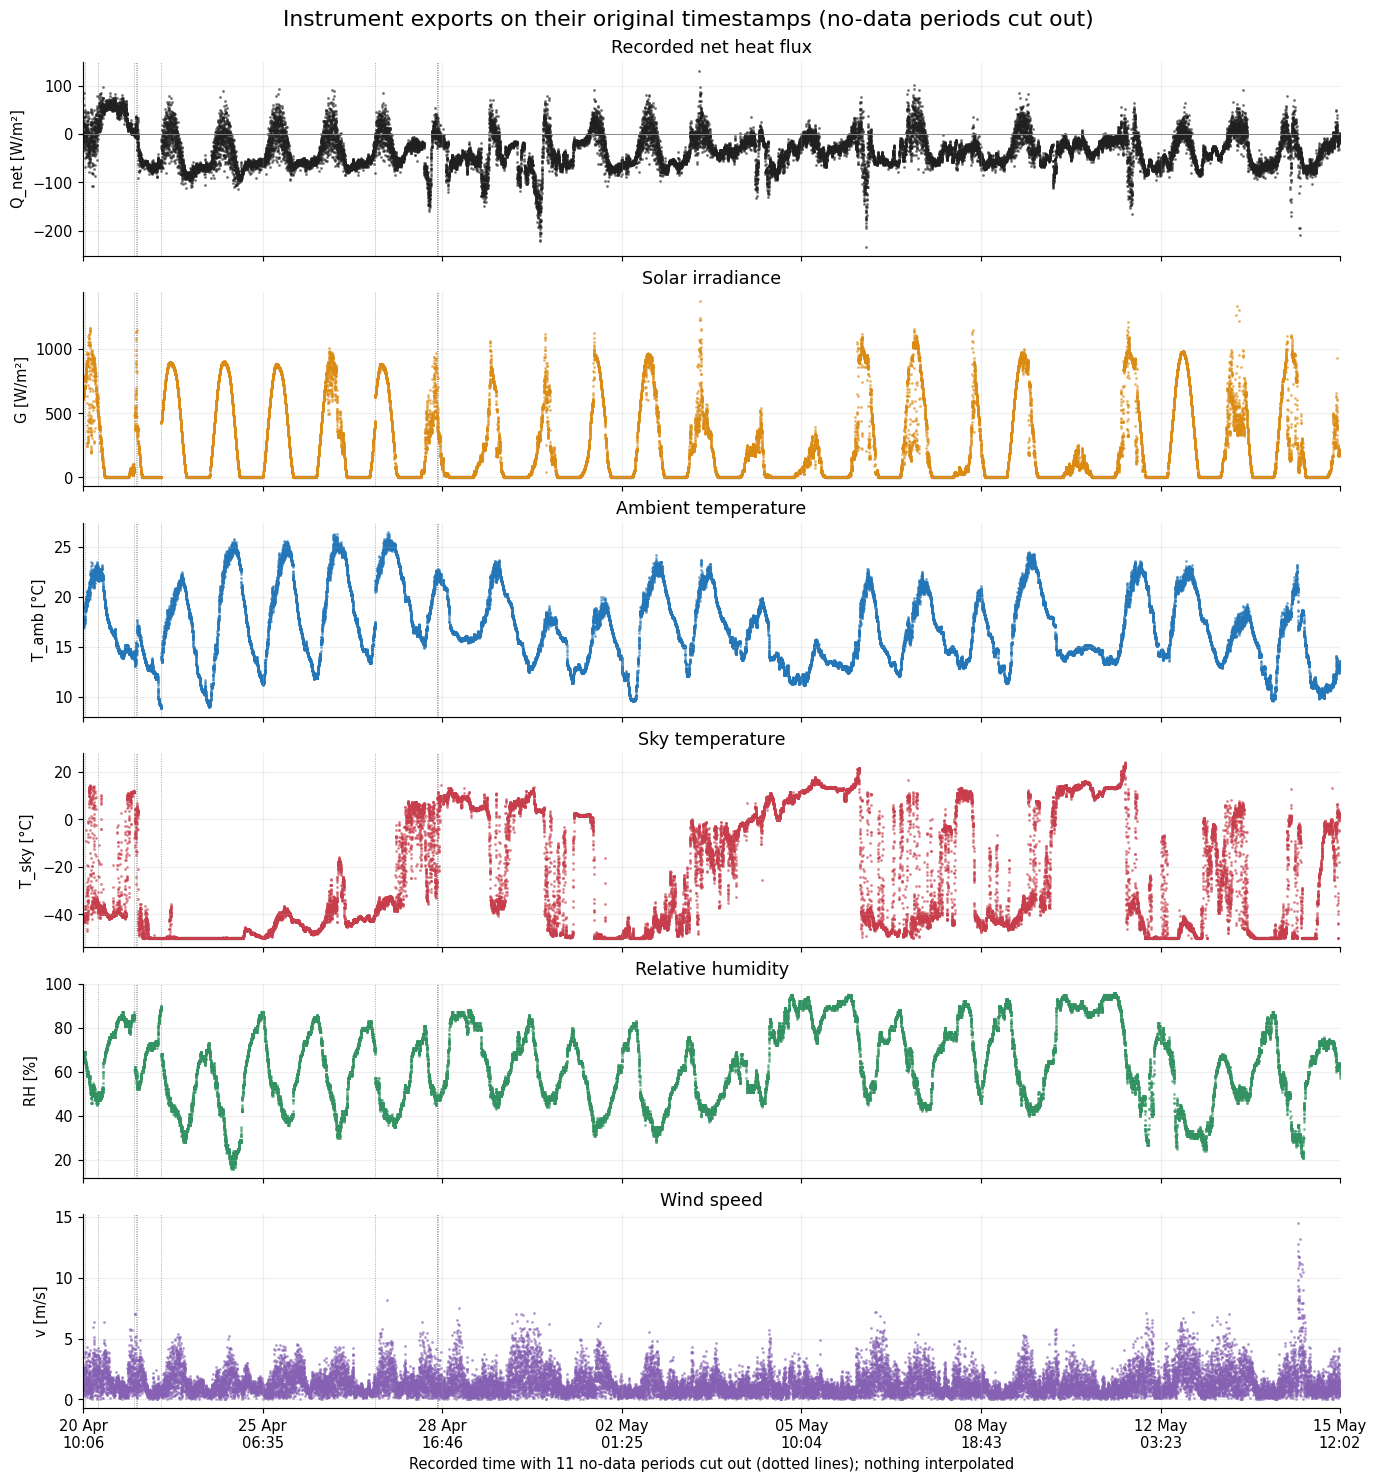

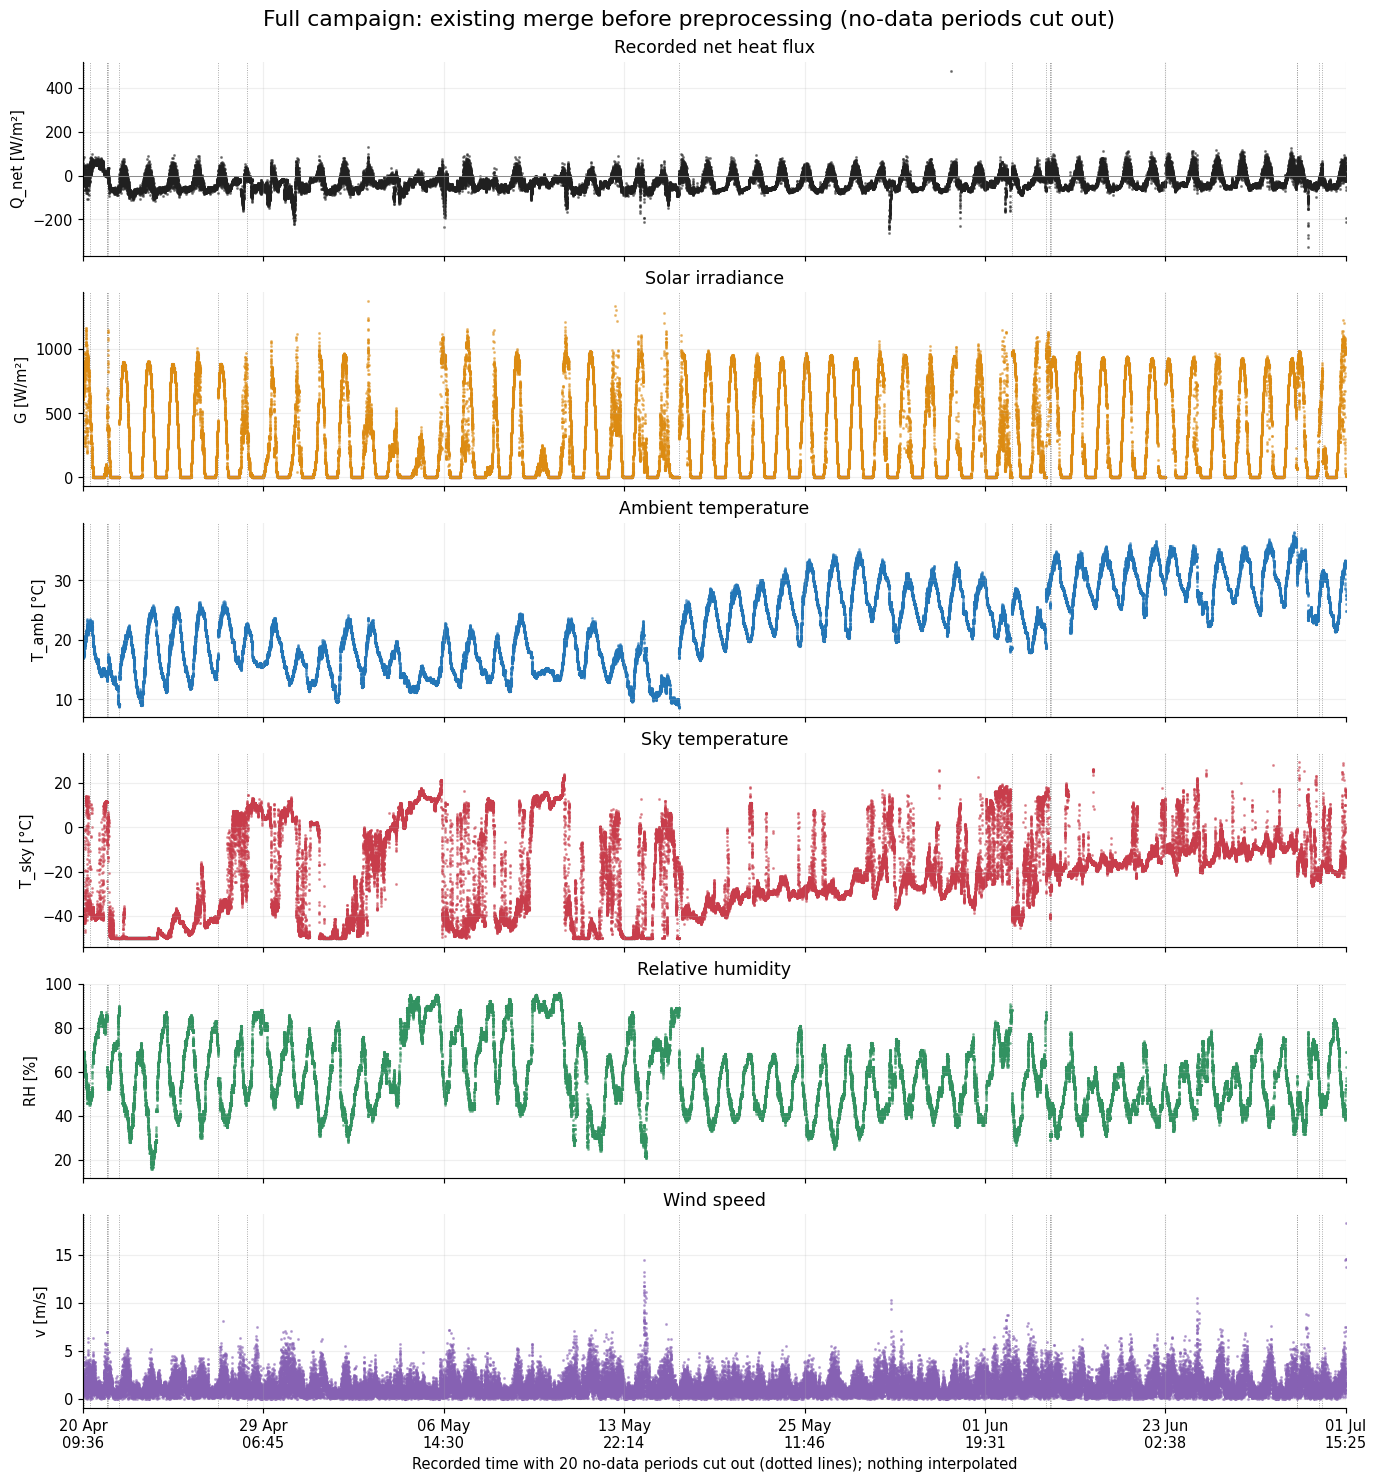

In [4]:
def date_axis(ax):
    locator = mdates.AutoDateLocator(minticks=5, maxticks=10)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

def mark_cuts(ax, index):
    """Faint dotted line wherever deleted (incomplete) intervals were cut out."""
    steps = pd.DatetimeIndex(index).to_series().diff().gt(pd.Timedelta(GRID)).to_numpy()
    for position in np.flatnonzero(steps):
        ax.axvline(position - 0.5, color='#9a9a9a', linewidth=0.6, linestyle=':', zorder=0)

def gapless_axis(ax, index, ticks=8):
    """Label a back-to-back (row-position) axis with the real timestamps."""
    index = pd.DatetimeIndex(index)
    positions = np.unique(np.linspace(0, len(index) - 1, ticks).round().astype(int))
    ax.set_xticks(positions, [index[p].strftime('%d %b\n%H:%M') for p in positions])
    ax.set_xlim(-0.5, len(index) - 0.5)

GAPLESS_XLABEL = 'Retained 3-min bins in time order (missing intervals deleted; dotted lines mark cuts)'

def compress_time(series_by_name, names):
    """Cut every period where any variable has no reading for > MAX_SOURCE_GAP.

    Readings inside a cut period are dropped (same rule as the cleaning); the
    remaining pieces are joined end to end on a shared, compressed time axis.
    """
    clean = {n: series_by_name[n].dropna().sort_index() for n in names}
    start = max(s.index.min() for s in clean.values())
    end = min(s.index.max() for s in clean.values())
    cuts = []
    for s in clean.values():
        t = s.loc[start:end].index
        step = t[1:] - t[:-1]
        big = step > MAX_SOURCE_GAP
        cuts += list(zip(t[:-1][big], t[1:][big]))
    merged = []
    for a, b in sorted(cuts):
        if merged and a <= merged[-1][1]:
            merged[-1][1] = max(merged[-1][1], b)
        else:
            merged.append([a, b])
    a = np.array([m[0].value for m in merged], dtype='int64')
    b = np.array([m[1].value for m in merged], dtype='int64')
    removed = np.concatenate([[0], np.cumsum(b - a)])
    origin = start.value

    def to_x(index):
        t = pd.DatetimeIndex(index).asi8
        return (t - removed[np.searchsorted(b, t, side='right')] - origin) / 86_400e9

    cut_x = (a - removed[:-1] - origin) / 86_400e9
    def to_time(x):
        k = np.searchsorted(cut_x, x, side='right')
        return pd.to_datetime(np.asarray(x) * 86_400e9 + origin + removed[k])

    kept = {}
    for n, s in clean.items():
        t = s.loc[start:end].index.asi8
        k = np.searchsorted(a, t, side='right') - 1
        inside = (k >= 0) & (t > a[np.maximum(k, 0)]) & (t < b[np.maximum(k, 0)])
        kept[n] = s.loc[start:end][~inside]
    return kept, to_x, to_time, cut_x

def plot_variables(series_by_name, title, points=False, gapless=False, compress=False):
    if compress:
        series_by_name, to_x, to_time, cut_x = compress_time(series_by_name, PLOT_ORDER)
    fig, axes = plt.subplots(6, 1, figsize=(13, 14), sharex=True, layout='constrained')
    for ax, name in zip(axes, PLOT_ORDER):
        series = series_by_name[name]
        label, unit, colour = LABELS[name]
        x = np.arange(len(series)) if gapless else series.index
        if compress:
            x = to_x(series.index)
            for position in cut_x:
                ax.axvline(position, color='#9a9a9a', linewidth=0.6, linestyle=':', zorder=0)
        if gapless:
            assert series.notna().all(), 'Gap-free plots require deleted missing rows.'
            mark_cuts(ax, series.index)
        if points:
            ax.scatter(x, series, s=1.2, alpha=0.45, color=colour, rasterized=True)
        else:
            ax.plot(x, series, linewidth=0.65, color=colour)
        ax.set(title=label, ylabel=unit)
        if name == TARGET:
            ax.axhline(0, color='grey', linewidth=0.6)
    if compress:
        span = max(to_x(s.index).max() for s in series_by_name.values())
        ticks = np.linspace(0, span, 8)
        axes[-1].set_xticks(ticks, [t.strftime('%d %b\n%H:%M') for t in to_time(ticks)])
        axes[-1].set_xlim(0, span)
        axes[-1].set_xlabel(f'Recorded time with {len(cut_x)} no-data periods cut out (dotted lines); nothing interpolated')
    elif gapless:
        gapless_axis(axes[-1], series.index)
        axes[-1].set_xlabel(GAPLESS_XLABEL)
    else:
        date_axis(axes[-1])
        axes[-1].set_xlabel('Recorded timestamp (timezone not supplied)')
    fig.suptitle(title, fontsize=15)
    plt.show()
    plt.close(fig)

plot_variables(native_series, 'Instrument exports on their original timestamps (no-data periods cut out)',
               points=True, compress=True)
plot_variables({name: full[name] for name in MODEL_COLS},
               'Full campaign: existing merge before preprocessing (no-data periods cut out)',
               points=True, compress=True)

## 3. Missing intervals, moving average and common time grid

First audit unsmoothed values on midnight-anchored, left-closed three-minute bins.
Only bins containing finite readings of all six required variables are eligible.
Within those eligible intervals, smooth each native series **before** taking its
three-minute bin mean. This retains MATLAB's sample-based order while respecting
the PDF's prohibition on filling missing intervals.

Smoothing restarts at a missing reading, an excluded common interval, or a native
timestamp gap greater than three minutes. This explicit conservative gap rule is
an adaptation, not a parameter found in MATLAB. Short segment endpoints use fewer
than 20 readings, as reported below. No interpolation is used at any stage.

The grid defines the interval assigned to each row; the centered moving average
uses neighboring observations. Its actual source support is recorded separately.
This is offline processed-signal reconstruction, not instantaneous forecasting.


In [5]:
def bin_series(series):
    resampler = series.resample(GRID, origin='start_day', closed='left', label='left')
    return resampler.mean(), resampler.count()

native_pairs = {name: bin_series(native_series[name]) for name in MODEL_COLS}
native_grid = pd.concat({name: pair[0] for name, pair in native_pairs.items()}, axis=1)
native_counts = pd.concat({name: pair[1] for name, pair in native_pairs.items()}, axis=1).fillna(0)
# Restrict to complete grid intervals inside the common acquisition time range.
overlap_start = max(series.index.min() for series in native_series.values())
overlap_end = min(series.index.max() for series in native_series.values())
common_index = native_grid.index[(native_grid.index >= overlap_start.ceil(GRID)) &
                                 (native_grid.index + pd.Timedelta(GRID) <= overlap_end)]
raw_aligned = native_grid.reindex(common_index)
counts = native_counts.reindex(common_index).astype(int)
complete = raw_aligned[MODEL_COLS].notna().all(axis=1)

def smooth_native(series, eligible_bins, window=MOVING_WINDOW):
    """MATLAB even-window centering, limited to uninterrupted eligible segments."""
    if window < 2 or window % 2:
        raise ValueError('Use an even sample window of at least two.')
    bins = series.index.floor(GRID)
    eligible = pd.Series(eligible_bins.reindex(bins, fill_value=False).to_numpy(), index=series.index)
    valid = series.notna() & eligible
    delta = series.index.to_series().diff()
    # A gap of more than one grid step between occupied bins crosses an excluded bin.
    bin_delta = pd.Series(bins, index=series.index).diff()
    boundaries = (~valid | ~valid.shift(fill_value=False) |
                  delta.gt(MAX_SOURCE_GAP) | bin_delta.gt(pd.Timedelta(GRID)))
    groups = boundaries.cumsum()
    result = pd.DataFrame(index=series.index, columns=['value', 'samples'], dtype=float)
    result['support_start'] = pd.NaT
    result['support_end'] = pd.NaT
    for _, segment in series.loc[valid].groupby(groups.loc[valid]):
        size = len(segment)
        position = np.arange(size)
        left = np.maximum(0, position - window // 2)
        right = np.minimum(size, position + window // 2)
        result.loc[segment.index, 'value'] = segment.rolling(window, center=True, min_periods=1).mean()
        result.loc[segment.index, 'samples'] = right - left
        result.loc[segment.index, 'support_start'] = segment.index[left].to_numpy()
        result.loc[segment.index, 'support_end'] = segment.index[right-1].to_numpy()
    assert result.loc[~valid, 'value'].isna().all()
    return result

# Independent examples verify even-window endpoint handling and gap isolation.
example_index = pd.date_range('2026-01-01', periods=40, freq='min')
example = pd.Series(np.arange(40, dtype=float), index=example_index)
example_eligible = pd.Series(True, index=example_index.floor(GRID).unique())
example_result = smooth_native(example, example_eligible)
expected = np.array([example.iloc[max(0,i-10):min(40,i+10)].mean() for i in range(40)])
np.testing.assert_allclose(example_result.value, expected)
assert example_result.samples.iloc[0] == 10 and example_result.samples.iloc[-1] == 11
gap_index = pd.to_datetime(['2026-01-01 00:00', '2026-01-01 00:01',
                           '2026-01-01 00:10', '2026-01-01 00:11'])
gap_series = pd.Series([0., 0., 100., 100.], index=gap_index)
gap_eligible = pd.Series(True, index=gap_index.floor(GRID).unique())
np.testing.assert_allclose(smooth_native(gap_series, gap_eligible).value, gap_series)
missing_example = example.copy()
missing_example.iloc[20] = np.nan
missing_result = smooth_native(missing_example, example_eligible)
assert pd.isna(missing_result.value.iloc[20])
assert missing_result.support_end.iloc[19] < example_index[20]
assert missing_result.support_start.iloc[21] > example_index[20]
excluded_example = example_eligible.copy()
excluded_example.iloc[4] = False
excluded_result = smooth_native(example, excluded_example)
assert excluded_result.loc[example_index.floor(GRID) == excluded_example.index[4], 'value'].isna().all()

smoothed_native = {name: smooth_native(native_series[name], complete) for name in MODEL_COLS}
aligned = pd.concat({name: bin_series(table.value)[0] for name, table in smoothed_native.items()}, axis=1)
aligned = aligned.reindex(common_index)[MODEL_COLS]
assert aligned.notna().all(axis=1).equals(complete)
model_data = aligned.loc[complete].copy()
rejected = aligned.index[~complete]
support_starts = pd.concat({name: table.support_start.resample(GRID).min()
                           for name, table in smoothed_native.items()}, axis=1).reindex(model_data.index)
support_ends = pd.concat({name: table.support_end.resample(GRID).max()
                         for name, table in smoothed_native.items()}, axis=1).reindex(model_data.index)
support = pd.DataFrame({'source_start': support_starts.min(axis=1),
                        'source_end': support_ends.max(axis=1)}, index=model_data.index)
assert support.notna().all().all()
assert np.isfinite(model_data.to_numpy()).all()
assert model_data.index.is_unique and model_data.index.is_monotonic_increasing
assert (counts.loc[model_data.index] >= 1).all().all()
assert len(model_data) > 100

smoothing_audit = pd.DataFrame([
    {'Variable': name, 'Smoothed readings': int(table.value.notna().sum()),
     'Shortened-window readings': int(table.samples.lt(MOVING_WINDOW).sum()),
     'Median support (min)': (table.support_end-table.support_start).dt.total_seconds().median()/60,
     'Maximum support (min)': (table.support_end-table.support_start).dt.total_seconds().max()/60}
    for name, table in smoothed_native.items()]).set_index('Variable')
display(smoothing_audit.round(3))
coverage = pd.DataFrame({'Observed bins': raw_aligned.notna().sum(),
                         'Missing bins': raw_aligned.isna().sum(),
                         'Coverage (%)': 100 * raw_aligned.notna().mean()})
display(coverage.loc[PLOT_ORDER])
display(pd.Series({'Grid slots': len(aligned), 'Complete retained bins': len(model_data),
                   'Excluded incomplete bins': len(rejected), 'Interpolated bins': 0,
                   'Moving-average samples': MOVING_WINDOW,
                   'First retained bin': model_data.index.min(),
                   'Last retained bin': model_data.index.max()}, name='Preparation').to_frame())

def missing_runs(mask):
    runs = []
    for _, segment in mask.groupby(mask.ne(mask.shift()).cumsum()):
        if segment.iloc[0]:
            runs.append({'Start': segment.index[0], 'End (exclusive)': segment.index[-1] + pd.Timedelta(GRID),
                         'Missing bins': len(segment), 'Hours': len(segment) * pd.Timedelta(GRID).total_seconds()/3600})
    return pd.DataFrame(runs, columns=['Start', 'End (exclusive)', 'Missing bins', 'Hours'])

gap_table = missing_runs(~complete).sort_values('Missing bins', ascending=False)
display(Markdown('**Largest excluded common-grid intervals**'))
display(gap_table.head(10).reset_index(drop=True))
native_gap_rows = []
for name, series in native_series.items():
    elapsed = series.index.to_series().diff()
    for timestamp in elapsed.index[elapsed.gt(MAX_SOURCE_GAP)]:
        native_gap_rows.append({'Variable': name, 'Previous reading': timestamp-elapsed.loc[timestamp],
                                'Next reading': timestamp, 'Gap minutes': elapsed.loc[timestamp].total_seconds()/60})
native_gaps = pd.DataFrame(native_gap_rows)
display(Markdown('**Largest native timestamp gaps (not interpolated)**'))
display(native_gaps.sort_values('Gap minutes', ascending=False).head(12))
display(Markdown('**Final processed table preview (physical units)**'))
display(model_data[[TARGET, 'T_amb', 'RH', 'G', 'v', 'T_sky']].head(10))


,Smoothed readings,Shortened-window readings,Median support (min),Maximum support (min)
Variable,,,,
T_amb,33908,198,19.0,19.033
RH,33908,198,19.0,19.033
v,33908,198,19.0,19.033
G,33908,198,19.0,19.033
T_sky,33882,189,19.0,21.513
Q_net,33892,192,19.0,20.883


,Observed bins,Missing bins,Coverage (%)
Q_net,11707,340,97.1777
G,11718,329,97.2690
T_amb,11718,329,97.2690
T_sky,11307,740,93.8574
RH,11718,329,97.2690
v,11718,329,97.2690


,Preparation
Grid slots,12047
Complete retained bins,11304
Excluded incomplete bins,743
Interpolated bins,0
Moving-average samples,20
First retained bin,2026-04-20 09:45:00
Last retained bin,2026-05-15 11:57:00


**Largest excluded common-grid intervals**

,Start,End (exclusive),Missing bins,Hours
0,2026-04-21 09:33:00,2026-04-22 10:15:00,494,24.70
1,2026-04-22 11:42:00,2026-04-22 17:57:00,125,6.25
2,2026-04-23 04:57:00,2026-04-23 09:00:00,81,4.05
3,2026-04-27 09:09:00,2026-04-27 10:09:00,20,1.00
4,2026-04-22 10:54:00,2026-04-22 11:09:00,5,0.25
5,2026-04-28 14:15:00,2026-04-28 14:30:00,5,0.25
6,2026-04-20 16:48:00,2026-04-20 17:00:00,4,0.20
7,2026-04-20 09:39:00,2026-04-20 09:45:00,2,0.10
8,2026-04-20 09:54:00,2026-04-20 10:00:00,2,0.10
9,2026-04-20 09:48:00,2026-04-20 09:51:00,1,0.05


**Largest native timestamp gaps (not interpolated)**

,Variable,Previous reading,Next reading,Gap minutes
33,Q_net,2026-04-17 17:38:51.000,2026-04-20 09:36:30.000,3837.6500
69,G,2026-04-17 17:41:24.000,2026-04-20 09:37:02.000,3835.6333
66,v,2026-04-17 17:41:24.000,2026-04-20 09:37:02.000,3835.6333
63,RH,2026-04-17 17:41:24.000,2026-04-20 09:37:02.000,3835.6333
60,T_amb,2026-04-17 17:41:24.000,2026-04-20 09:37:02.000,3835.6333
52,T_sky,2026-04-21 09:31:18.736,2026-04-22 10:15:48.460,1484.4954
70,G,2026-04-21 18:01:02.000,2026-04-22 10:16:54.000,975.8667
67,v,2026-04-21 18:01:02.000,2026-04-22 10:16:54.000,975.8667
64,RH,2026-04-21 18:01:02.000,2026-04-22 10:16:54.000,975.8667
61,T_amb,2026-04-21 18:01:02.000,2026-04-22 10:16:54.000,975.8667


**Final processed table preview (physical units)**

,Q_net,T_amb,RH,G,v,T_sky
timestamp,,,,,,
2026-04-20 09:45:00,23.6544,16.8000,68.3333,542.0000,1.5167,-42.9000
2026-04-20 09:51:00,-2.8072,16.6000,68.6667,566.3333,1.8067,-42.8000
2026-04-20 10:00:00,27.3476,16.7000,70.0000,584.3333,2.5400,-42.8000
2026-04-20 10:06:00,15.8022,17.2925,68.1551,613.1879,1.6938,-42.4640
2026-04-20 10:09:00,15.2234,17.3654,67.8379,617.3549,1.6516,-42.4606
2026-04-20 10:12:00,16.1896,17.3912,67.7271,620.5260,1.6920,-42.4766
2026-04-20 10:15:00,15.8359,17.4692,67.4930,623.8772,1.5844,-42.4911
2026-04-20 10:18:00,11.6508,17.4817,67.3667,629.4833,1.5115,-42.5617
2026-04-20 10:21:00,13.6381,17.4550,67.4333,637.3000,1.4825,-42.6133


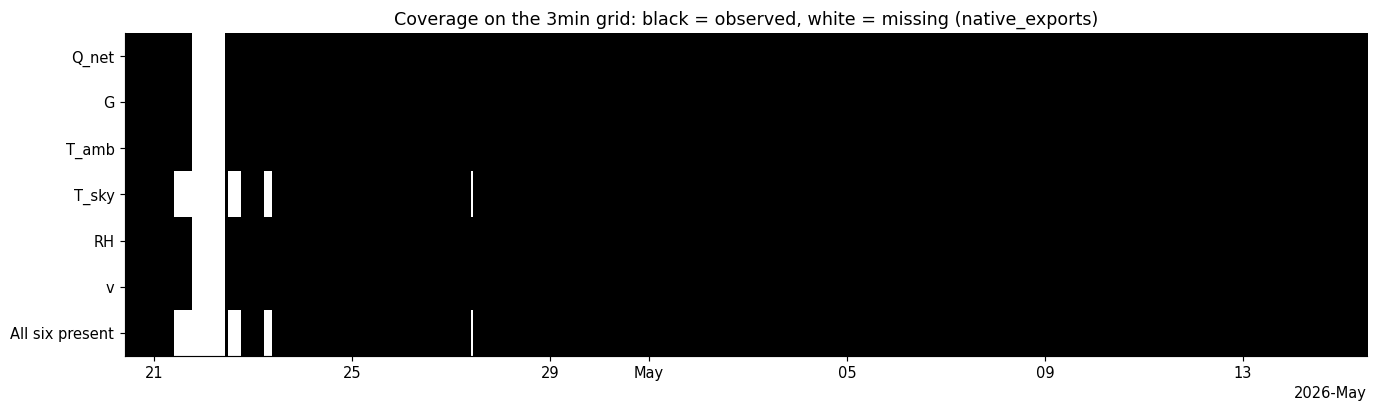

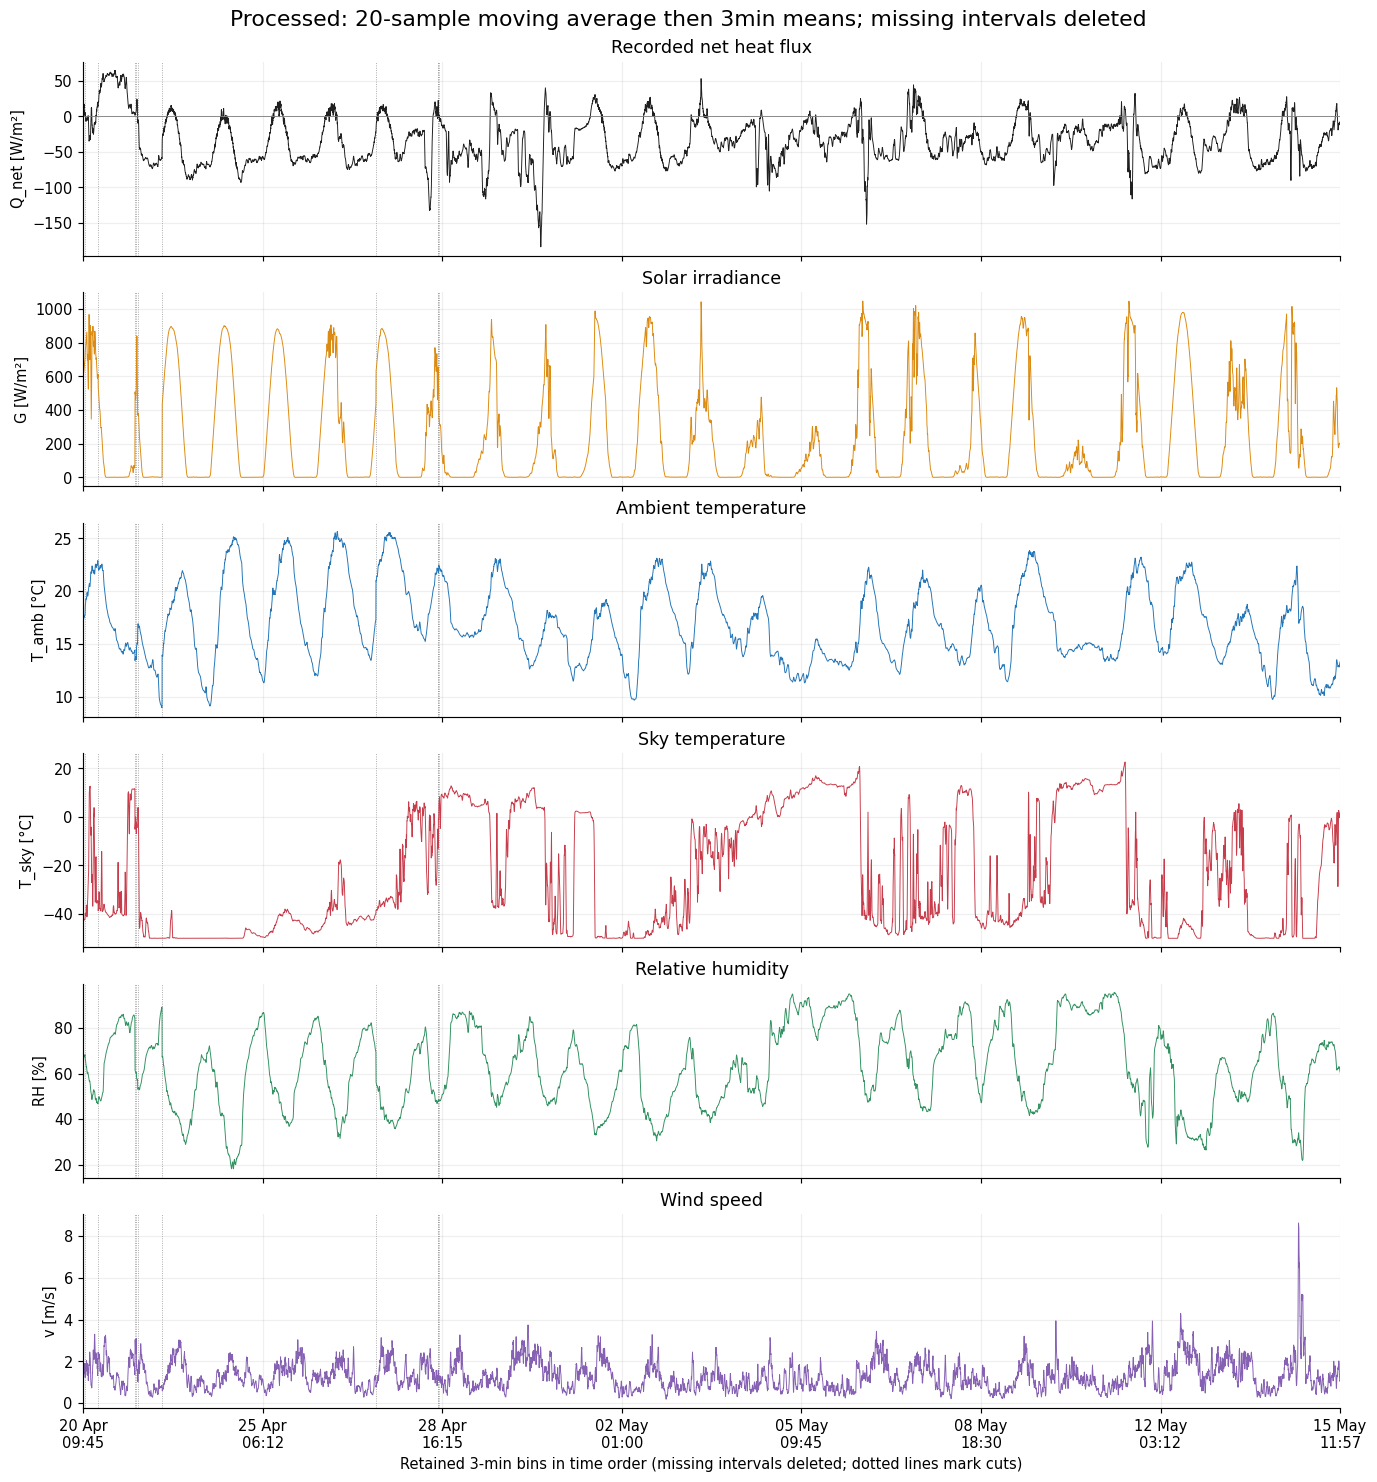

In [6]:
# Rows show per-variable availability before intersection; the last row is the model eligibility mask.
availability = np.vstack([raw_aligned[PLOT_ORDER].notna().to_numpy().T, complete.to_numpy()])
fig, ax = plt.subplots(figsize=(13, 3.8), layout='constrained')
start_num = mdates.date2num(aligned.index[0])
end_num = mdates.date2num(aligned.index[-1] + pd.Timedelta(GRID))
ax.imshow(availability, aspect='auto', interpolation='nearest', cmap='Greys', vmin=0, vmax=1,
          extent=[start_num, end_num, len(PLOT_ORDER)+0.5, -0.5])
ax.set_yticks(range(7), [*PLOT_ORDER, 'All six present'])
ax.set_title(f'Coverage on the {GRID} grid: black = observed, white = missing ({DATA_SCOPE})')
ax.grid(False)
ax.xaxis_date()
date_axis(ax)
plt.show()
plt.close(fig)

# Missing intervals are deleted (not filled); retained bins are drawn back-to-back, so no gaps.
assert model_data.notna().all().all() and len(model_data) == int(complete.sum())
plot_variables({name: model_data[name] for name in MODEL_COLS},
               f'Processed: 20-sample moving average then {GRID} means; missing intervals deleted',
               gapless=True)


### Individual time-series figures

These six full-size figures correspond to `Q_net_vs_time`, `G_vs_time`,
`T_amb_vs_time`, `T_sky_vs_time`, `RH_vs_time` and `v_vs_time` in the earlier
`figures_main_3` collection. They are regenerated from this notebook's selected
dataset on its three-minute grid after the 20-sample moving average. Rows with missing values are deleted and the remaining
bins are drawn back-to-back, so the curves have no gaps; faint dotted lines mark the
13 places where deleted intervals were cut out. Nothing is interpolated, and the
recorded heat-flux sign is preserved. The coverage and combined six-variable
figures appear immediately above. Every figure is displayed and stored inline;
no separate PNG or PDF is written.


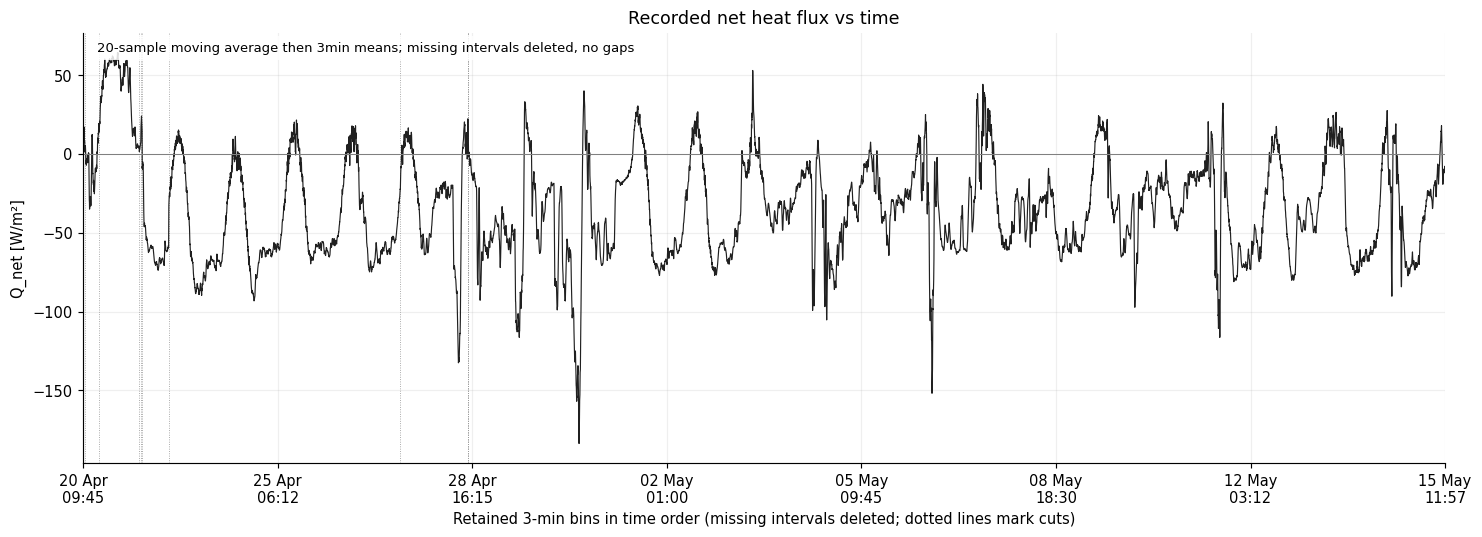

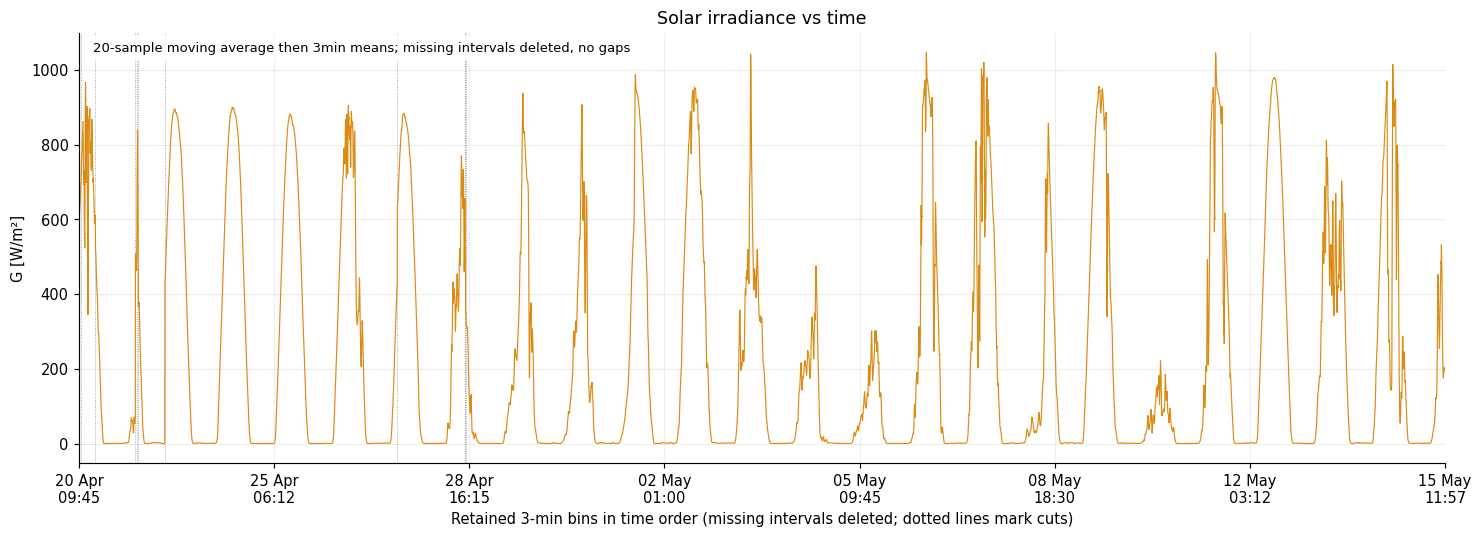

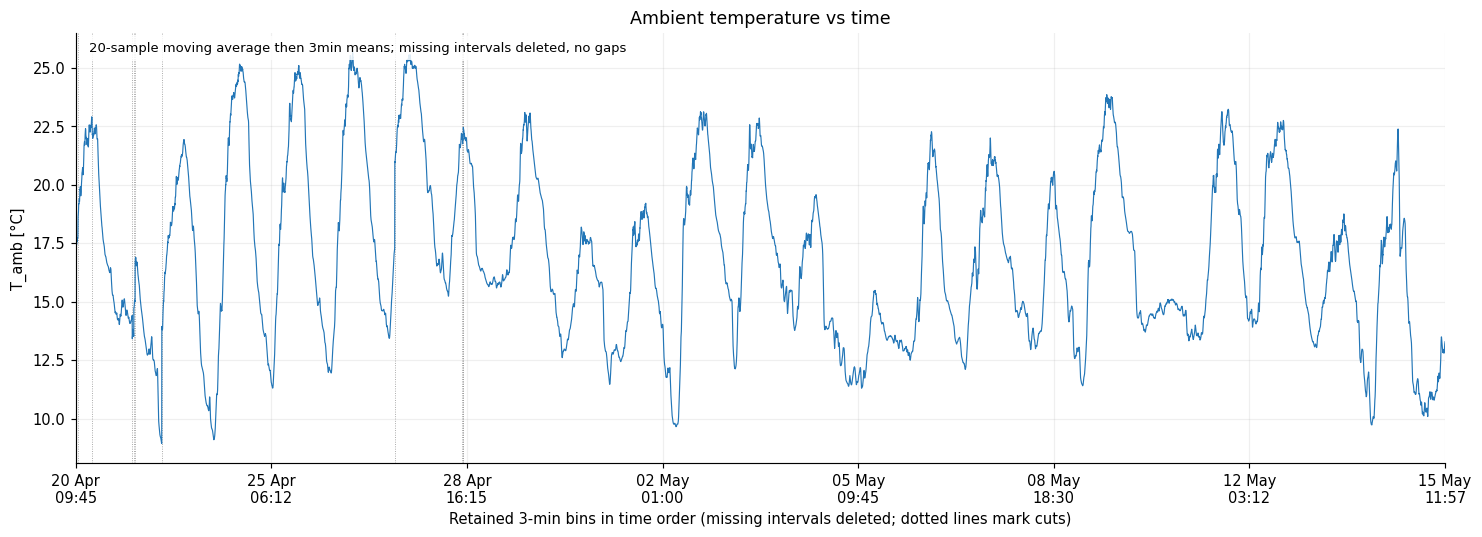

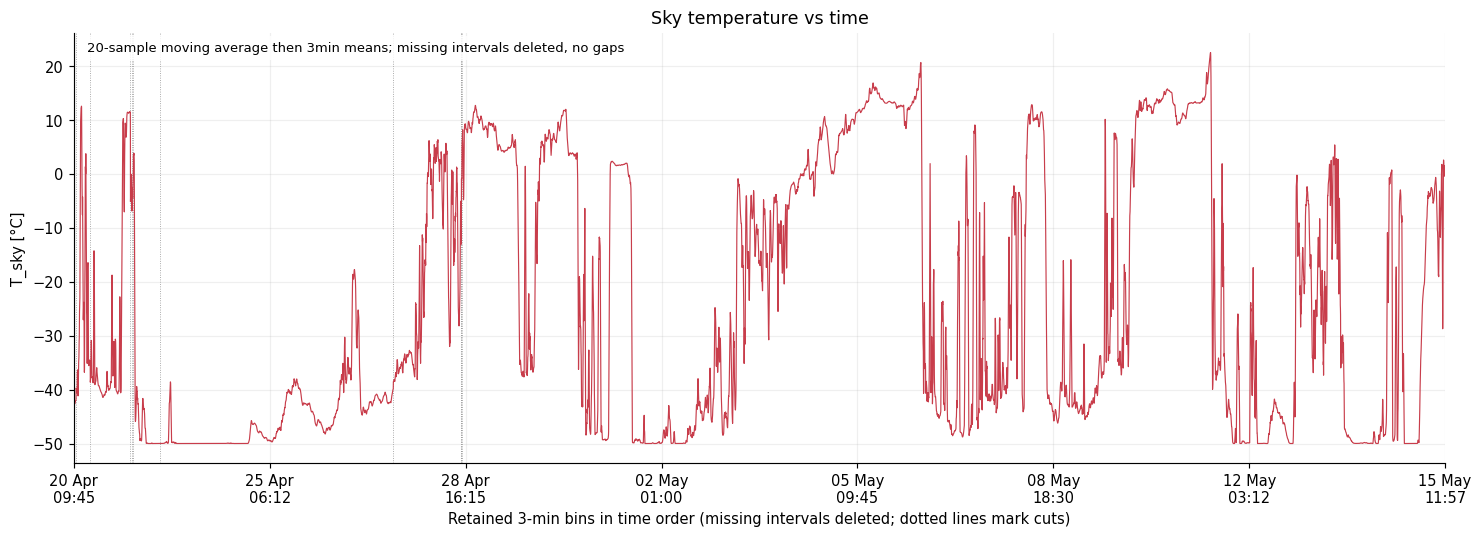

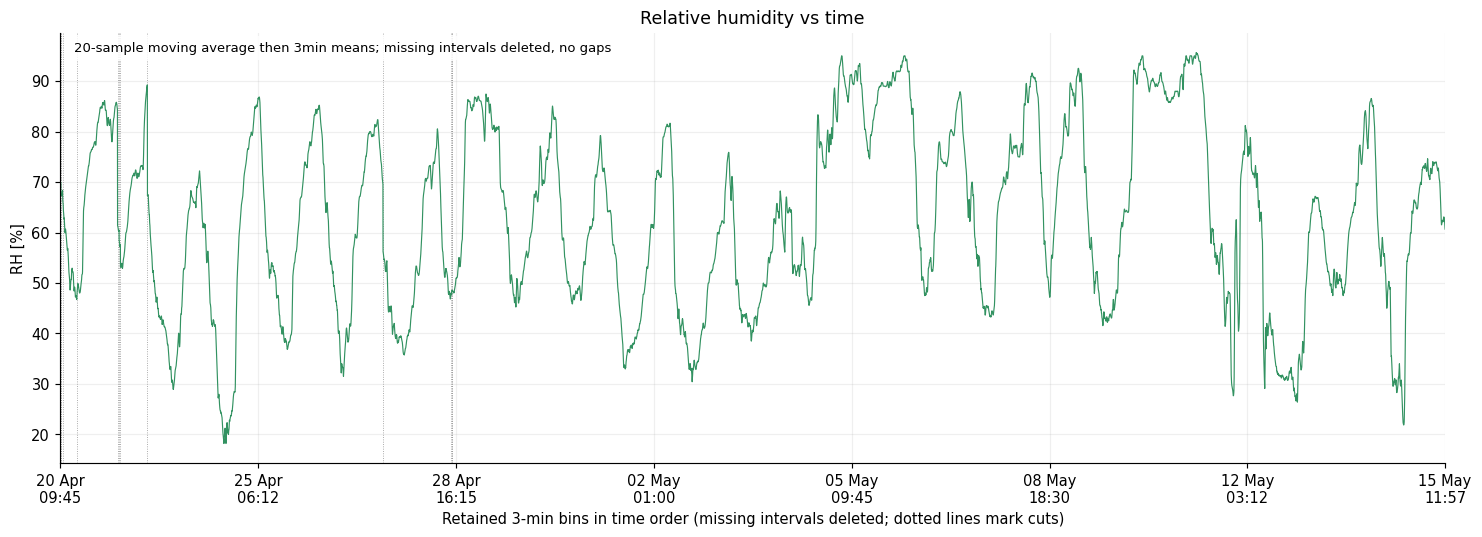

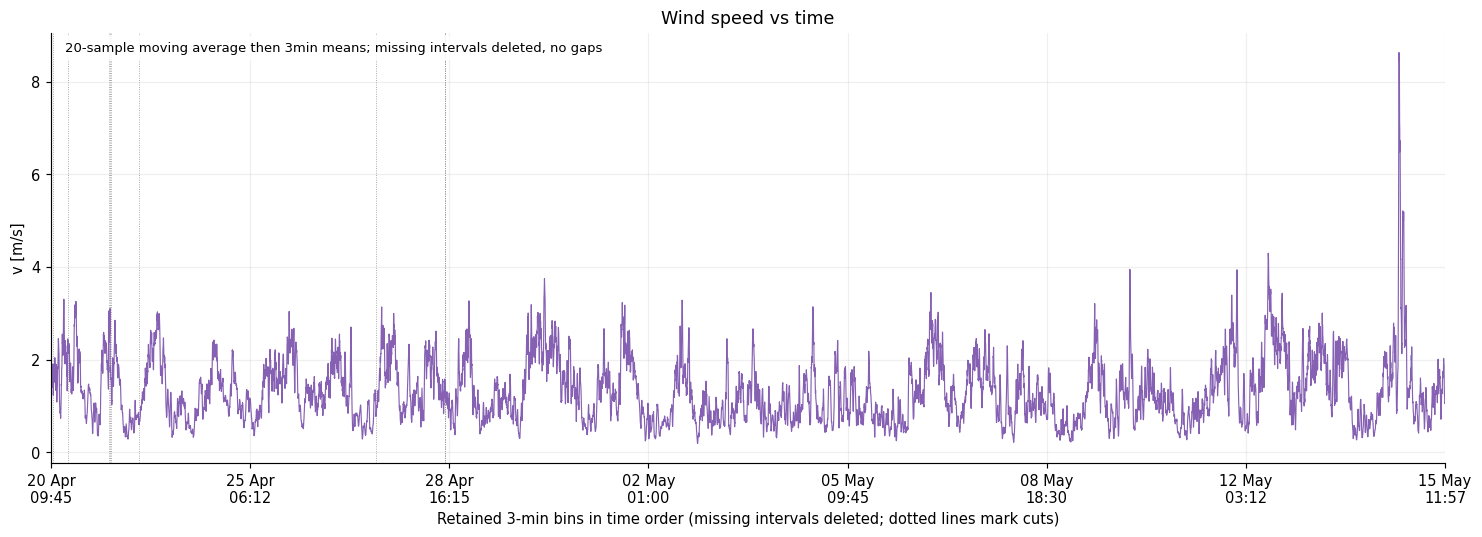

In [7]:
for name in PLOT_ORDER:
    title, unit, colour = LABELS[name]
    fig, ax = plt.subplots(figsize=(14, 5), layout='constrained')
    mark_cuts(ax, model_data.index)
    ax.plot(np.arange(len(model_data)), model_data[name], color=colour, linewidth=0.8)
    if name == TARGET:
        ax.axhline(0, color='grey', linewidth=0.7)
    ax.set(title=f'{title} vs time', ylabel=unit,
           xlabel=GAPLESS_XLABEL)
    gapless_axis(ax, model_data.index)
    ax.text(0.01, 0.98, f'20-sample moving average then {GRID} means; missing intervals deleted, no gaps',
            transform=ax.transAxes, va='top', fontsize=9,
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.85})
    plt.show()
    plt.close(fig)


### Compare acquisition and processing on the same time window

All six variables show the original readings, unsmoothed three-minute means and
the final moving-average-then-binned signals over the same three-day window.
Only retained (complete) bins are shown, drawn back-to-back without gaps. This
separates smoothing from bin averaging.


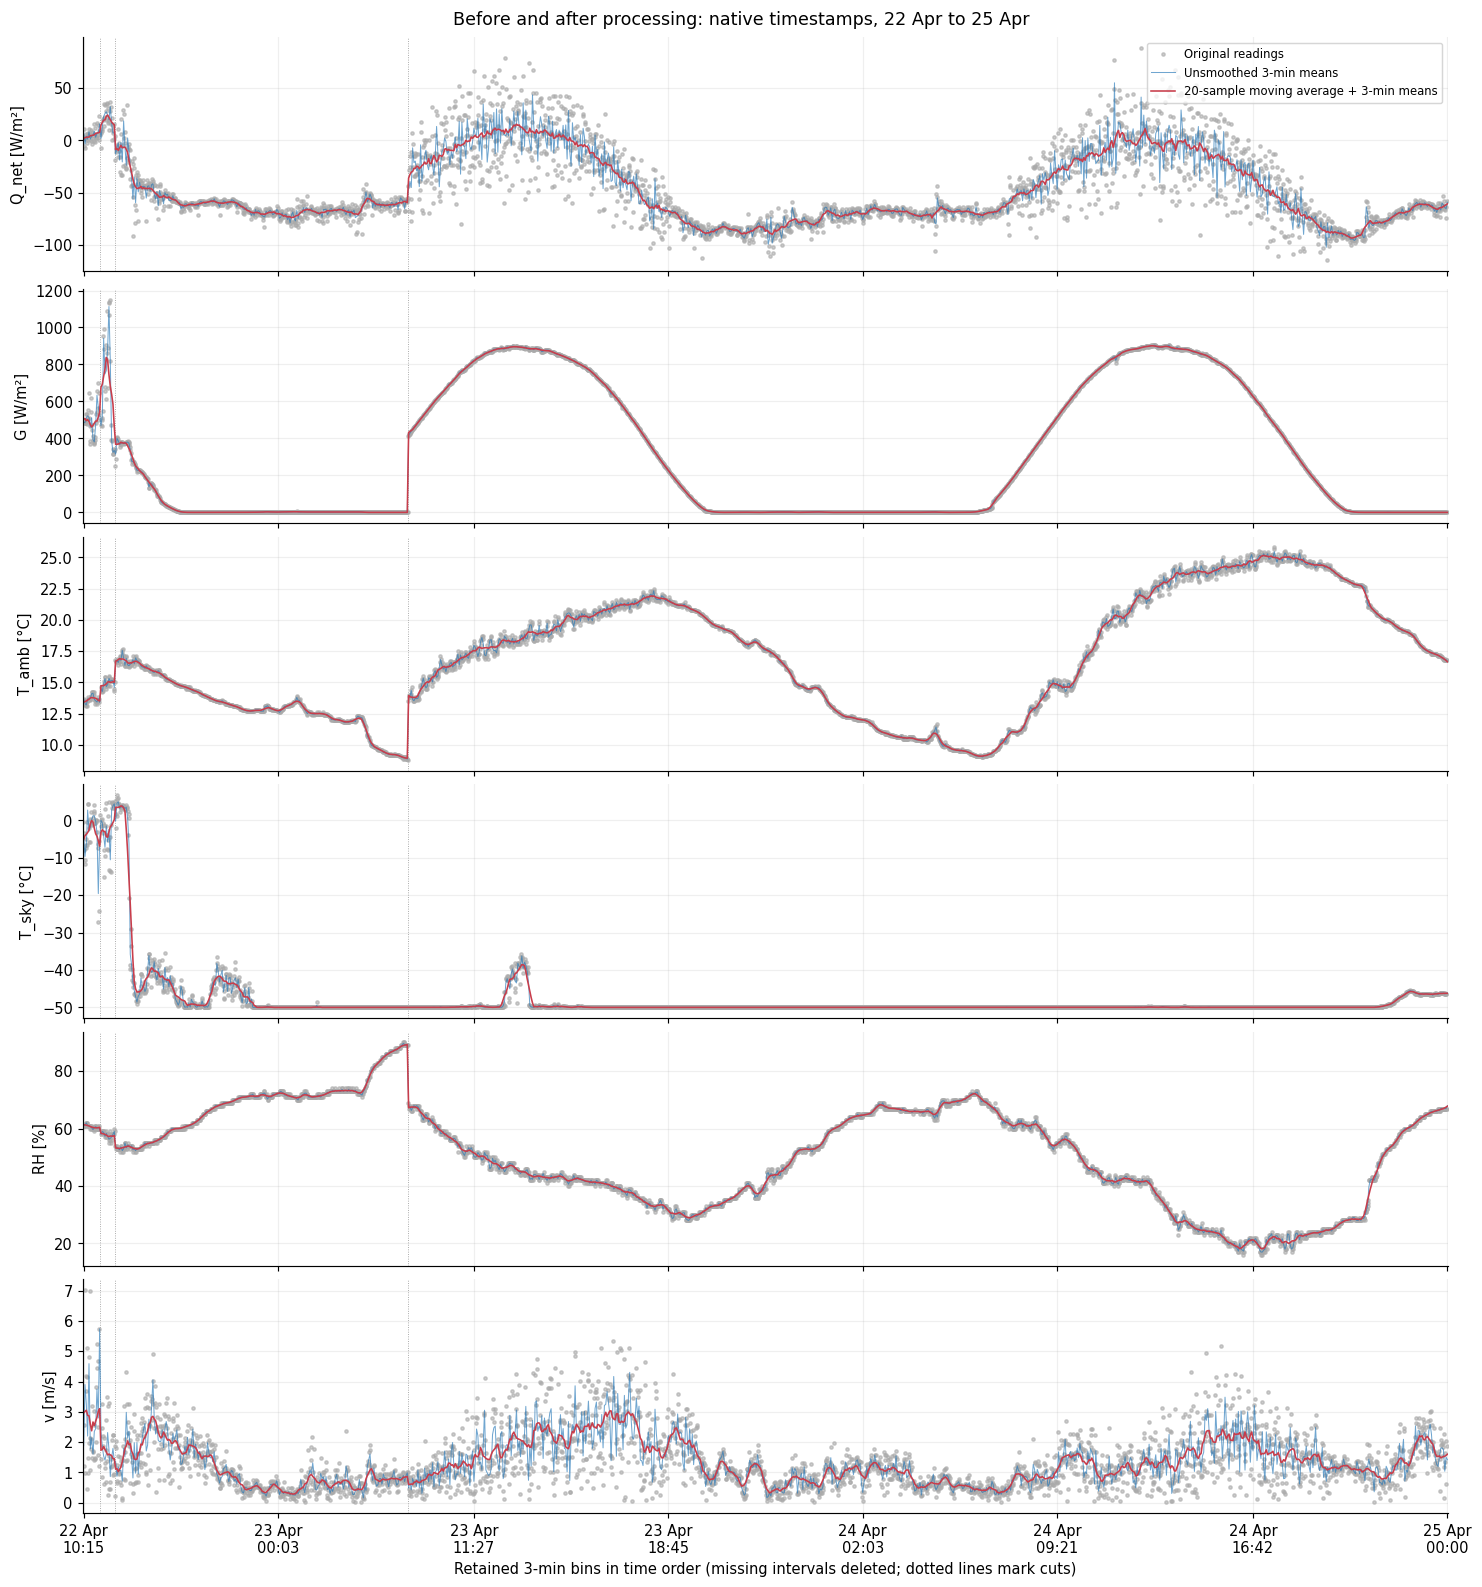

In [8]:
window_start = model_data.index.min().normalize() + pd.Timedelta('2D')
window_end = window_start + pd.Timedelta('3D')
fig, axes = plt.subplots(6, 1, figsize=(14, 15), sharex=True, layout='constrained')
window = model_data.loc[window_start:window_end]
for ax, name in zip(axes, PLOT_ORDER):
    readings = native_series[name].loc[window_start:window_end].dropna()
    slot = window.index.get_indexer(readings.index.floor(GRID))
    keep = slot >= 0  # readings inside deleted intervals are dropped too
    offset = (readings.index - readings.index.floor(GRID)) / pd.Timedelta(GRID)
    mark_cuts(ax, window.index)
    ax.scatter(slot[keep] + offset[keep] - 0.5, readings[keep], color='#aaaaaa', s=5, alpha=0.6,
               label='Original readings')
    ax.plot(np.arange(len(window)), raw_aligned.loc[window.index, name], color='#2376b7', alpha=0.65,
            linewidth=0.7, label='Unsmoothed 3-min means')
    ax.plot(np.arange(len(window)), window[name], color='#c83d4b', linewidth=1.1,
            label='20-sample moving average + 3-min means')
    ax.set_ylabel(LABELS[name][1])
axes[0].legend(loc='upper right', fontsize=8)
gapless_axis(axes[-1], window.index)
axes[-1].set_xlabel(GAPLESS_XLABEL)
fig.suptitle(f'Before and after processing: native timestamps, {window_start:%d %b} to {window_end:%d %b}')
plt.show()
plt.close(fig)


## 4. Data checks and descriptive relationships

,count,mean,std,min,1%,50%,99%,max
T_amb,11304.0,16.9065,3.7182,8.9361,9.8301,16.3842,25.0349,25.6517
RH,11304.0,62.8662,17.9737,18.2000,24.7692,62.9667,94.4000,95.6500
v,11304.0,1.3302,0.6998,0.1917,0.3265,1.1993,3.1587,8.6298
G,11304.0,229.0738,307.1608,0.0000,0.0000,40.2917,954.1385,1046.9500
T_sky,11304.0,-23.9659,23.8438,-50.0000,-50.0000,-34.3117,15.7714,22.5767
Q_net,11304.0,-34.2855,32.9700,-183.8180,-109.5049,-36.1773,56.1719,64.4298


,Count
Sky values exactly -50 °C (input readings),4245
RH outside 0–100% (input readings),0
Negative wind speed (input readings),0
Negative solar irradiance (input readings),0
"Retained bins with |Q_net| > 100 W/m² (review, not automatic rejection)",158


**Ten largest recorded absolute target values after binning**

,T_amb,RH,v,G,T_sky,Q_net
timestamp,,,,,,
2026-04-30 12:36:00,14.7783,55.1833,2.5865,298.9833,3.7900,-183.8180
2026-04-30 12:33:00,14.7767,55.4167,2.6348,297.8167,3.8017,-181.4708
2026-04-30 12:39:00,14.8117,55.0833,2.4050,304.3167,3.7850,-180.6573
2026-04-30 12:30:00,14.7783,55.7500,2.6975,302.9500,3.8567,-178.9935
2026-04-30 12:42:00,14.8933,54.9667,2.2202,313.7667,3.7900,-177.6009
2026-04-30 12:27:00,14.8167,56.1833,2.6198,310.9333,3.8933,-170.1941
2026-04-30 12:45:00,15.0183,54.9333,2.0545,327.1667,3.7283,-168.9776
2026-04-30 12:24:00,14.8683,56.7833,2.6162,318.5000,3.8983,-161.7801
2026-04-30 12:48:00,15.1250,54.7500,2.0038,342.9833,3.6533,-161.0839


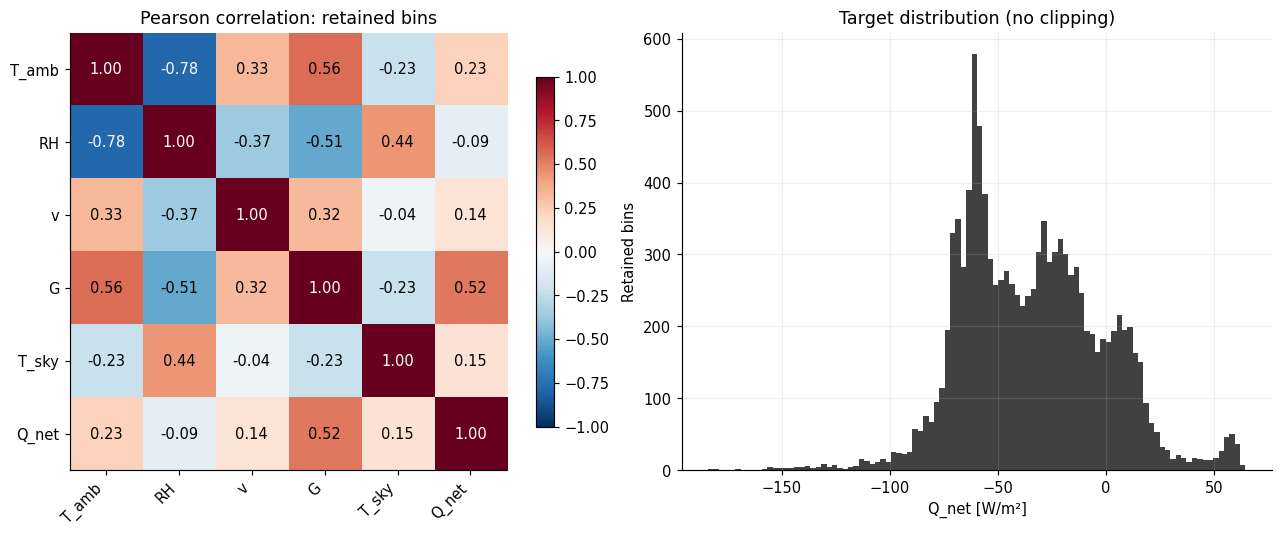

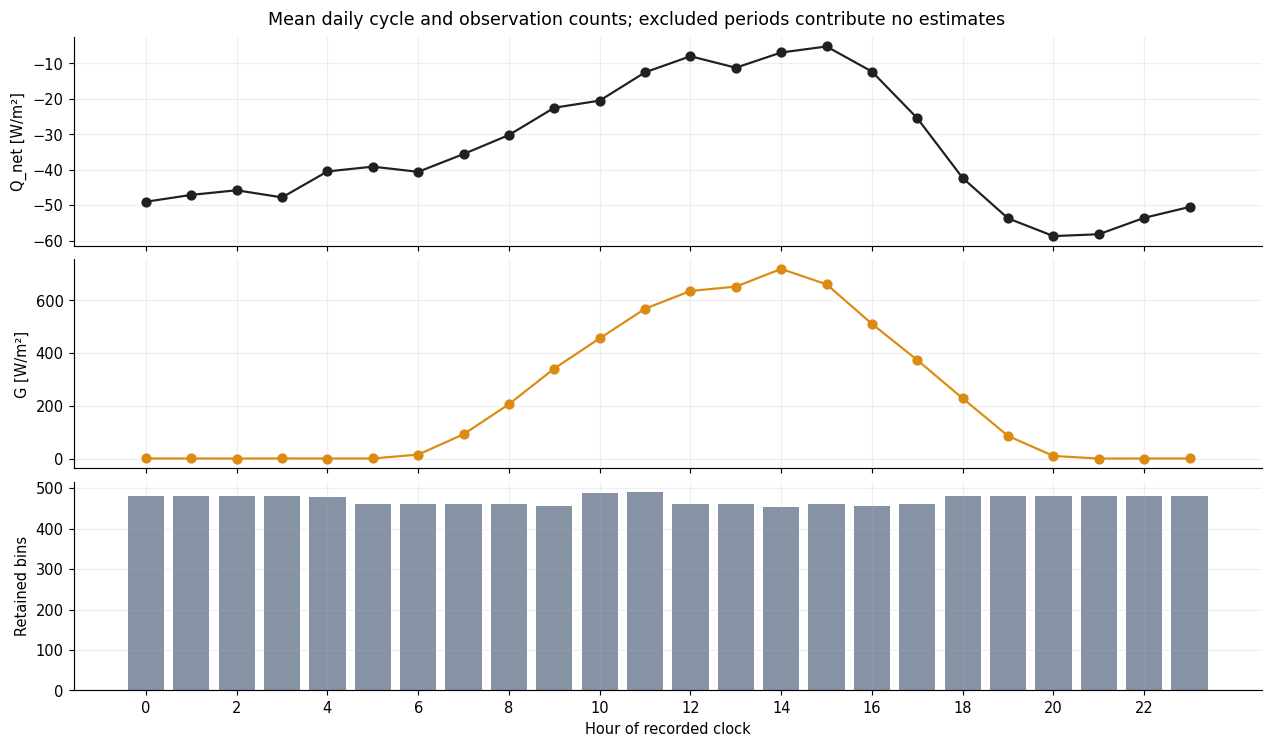

In [9]:
display(model_data.describe(percentiles=[0.01, 0.5, 0.99]).T)
input_for_checks = full[MODEL_COLS] if DATA_SCOPE == 'full_campaign' else native_full[MODEL_COLS]
flags = pd.Series({
    'Sky values exactly -50 °C (input readings)': int(input_for_checks['T_sky'].eq(-50).sum()),
    'RH outside 0–100% (input readings)': int((input_for_checks['RH'].lt(0) | input_for_checks['RH'].gt(100)).sum()),
    'Negative wind speed (input readings)': int(input_for_checks['v'].lt(0).sum()),
    'Negative solar irradiance (input readings)': int(input_for_checks['G'].lt(0).sum()),
    'Retained bins with |Q_net| > 100 W/m² (review, not automatic rejection)': int(model_data[TARGET].abs().gt(100).sum()),
}, name='Count')
display(flags.to_frame())
display(Markdown('**Ten largest recorded absolute target values after binning**'))
display(model_data.loc[model_data[TARGET].abs().nlargest(10).index])

correlation = model_data[MODEL_COLS].corr()
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
im = axes[0].imshow(correlation, cmap='RdBu_r', vmin=-1, vmax=1)
axes[0].set_xticks(range(6), MODEL_COLS, rotation=45, ha='right')
axes[0].set_yticks(range(6), MODEL_COLS)
axes[0].grid(False)
for row in range(6):
    for col in range(6):
        value = correlation.iloc[row, col]
        axes[0].text(col, row, f'{value:.2f}', ha='center', va='center',
                     color='white' if abs(value) > 0.65 else 'black')
axes[0].set_title('Pearson correlation: retained bins')
fig.colorbar(im, ax=axes[0], shrink=0.8)
axes[1].hist(model_data[TARGET], bins=100, color=LABELS[TARGET][2], alpha=0.85)
axes[1].set(xlabel=LABELS[TARGET][1], ylabel='Retained bins', title='Target distribution (no clipping)')
plt.show()
plt.close(fig)

hour_groups = model_data.groupby(model_data.index.hour)
hourly_means = hour_groups[[TARGET, 'G']].mean()
hourly_counts = hour_groups.size()
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True, layout='constrained')
for ax, name in zip(axes[:2], [TARGET, 'G']):
    ax.plot(hourly_means.index, hourly_means[name], marker='o', color=LABELS[name][2])
    ax.set_ylabel(LABELS[name][1])
axes[2].bar(hourly_counts.index, hourly_counts, color='#8693a5')
axes[2].set(xlabel='Hour of recorded clock', ylabel='Retained bins', xticks=range(0, 24, 2))
fig.suptitle('Mean daily cycle and observation counts; excluded periods contribute no estimates')
plt.show()
plt.close(fig)

### Mean daily cycle: net heat flux and solar irradiance

This reproduces the two-axis layout of `02_mean_daily_cycle` using only the retained
observations. Read heat flux against the left axis and solar irradiance against the
right axis; the heights of the two curves are not directly comparable. The separate
panels and observation counts above provide the same information without dual axes.

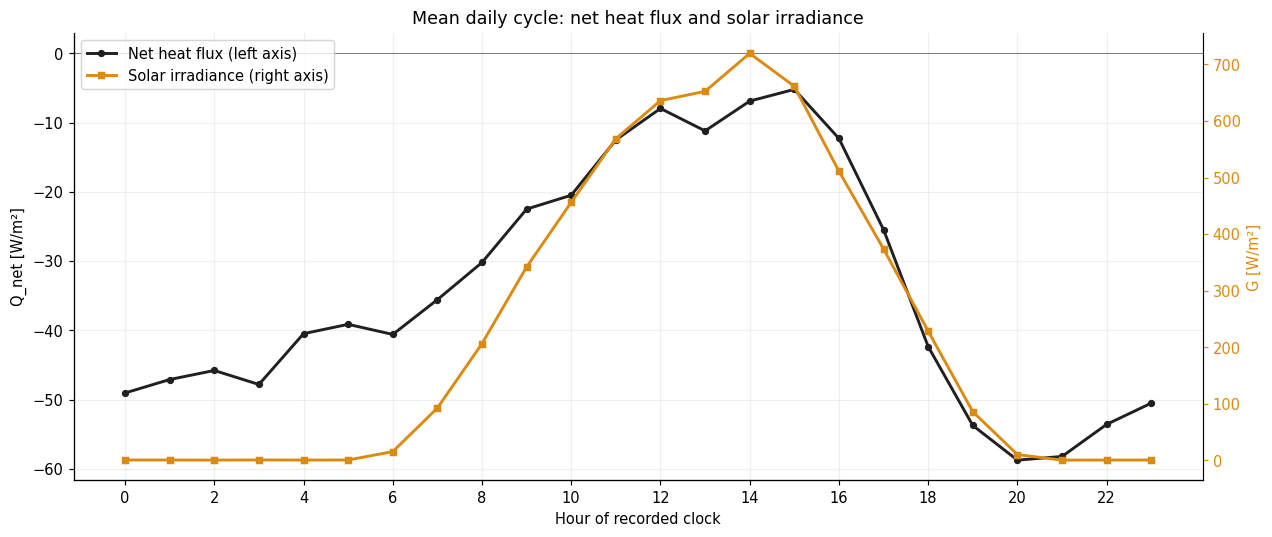

In [10]:
daily_cycle = model_data.groupby(model_data.index.hour)[[TARGET, 'G']].mean()
fig, flux_axis = plt.subplots(figsize=(12, 5), layout='constrained')
solar_axis = flux_axis.twinx()
flux_line, = flux_axis.plot(daily_cycle.index, daily_cycle[TARGET], marker='o',
                            linewidth=2, markersize=4, color=LABELS[TARGET][2],
                            label='Net heat flux (left axis)')
solar_line, = solar_axis.plot(daily_cycle.index, daily_cycle['G'], marker='s',
                              linewidth=2, markersize=4, color=LABELS['G'][2],
                              label='Solar irradiance (right axis)')
flux_axis.axhline(0, color='grey', linewidth=0.7)
flux_axis.set(xlabel='Hour of recorded clock', ylabel=LABELS[TARGET][1],
              xticks=range(0, 24, 2), title='Mean daily cycle: net heat flux and solar irradiance')
solar_axis.set_ylabel(LABELS['G'][1], color=LABELS['G'][2])
solar_axis.tick_params(axis='y', colors=LABELS['G'][2])
solar_axis.spines['right'].set_visible(True)
solar_axis.grid(False)
flux_axis.legend(handles=[flux_line, solar_line], loc='upper left')
plt.show()
plt.close(fig)

### Standalone correlation heatmap

This is the full-size counterpart of `03_correlation_heatmap`. It uses the same
retained-bin Pearson correlations as the diagnostic panel above. Correlations are
descriptive associations, not causal effects or measures of prediction accuracy.

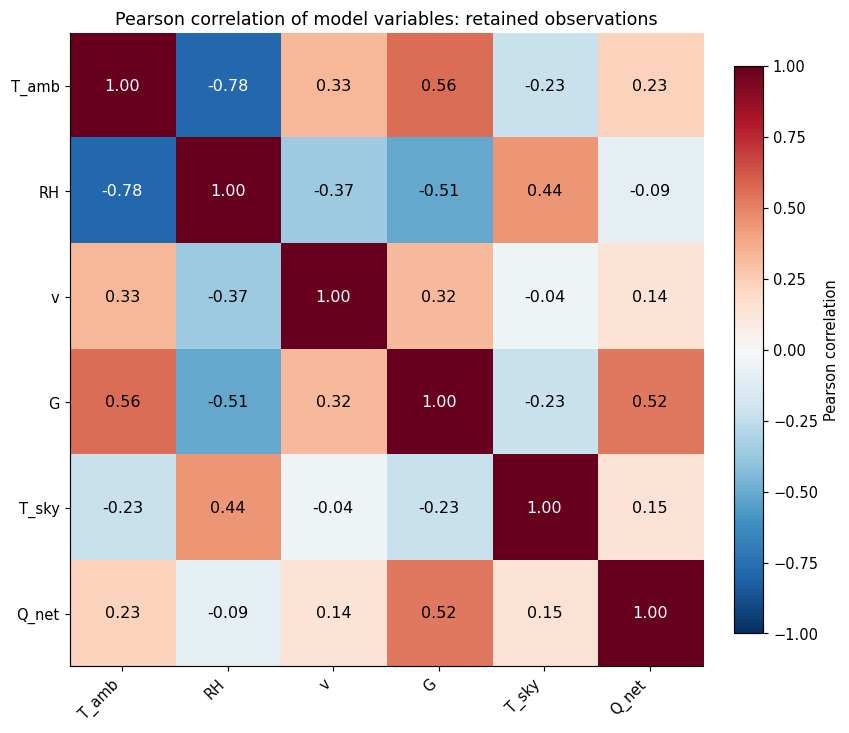

In [11]:
standalone_correlation = model_data[MODEL_COLS].corr()
fig, ax = plt.subplots(figsize=(8, 7), layout='constrained')
colour_map = ax.imshow(standalone_correlation, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(MODEL_COLS)), MODEL_COLS, rotation=45, ha='right')
ax.set_yticks(range(len(MODEL_COLS)), MODEL_COLS)
for row in range(len(MODEL_COLS)):
    for column in range(len(MODEL_COLS)):
        value = standalone_correlation.iloc[row, column]
        ax.text(column, row, f'{value:.2f}', ha='center', va='center', fontsize=11,
                color='white' if abs(value) > 0.65 else 'black')
ax.set_title('Pearson correlation of model variables: retained observations')
ax.grid(False)
fig.colorbar(colour_map, ax=ax, shrink=0.85, label='Pearson correlation')
plt.show()
plt.close(fig)

## 5. Fixed training and validation splits

The requested shuffled 80/20 split uses seed 42. Nearby observations share centered
smoothing windows, so shuffled validation is a within-campaign reconstruction
benchmark, not an independent future forecast. No tuning is performed on it.

A second evaluation reserves the last 20% chronologically and removes at least
24 hours before it from training. Actual raw support ranges are checked to ensure
that **no training window shares source observations with validation**. This is a
stronger temporal test, although centered preprocessing still uses future neighbors
within the validation period and is unsuitable for real-time predictions.


Chronological train/validation raw support ranges are disjoint.


,Training bins,Validation bins,Unused gap bins,Training first,Training last,Validation first,Validation last
Evaluation,,,,,,,
Random 80/20,9043,2261,0,2026-04-20 09:51:00,2026-05-15 11:57:00,2026-04-20 09:45:00,2026-05-15 11:54:00
Chronological holdout,8563,2261,480,2026-04-20 09:45:00,2026-05-09 18:54:00,2026-05-10 18:57:00,2026-05-15 11:57:00


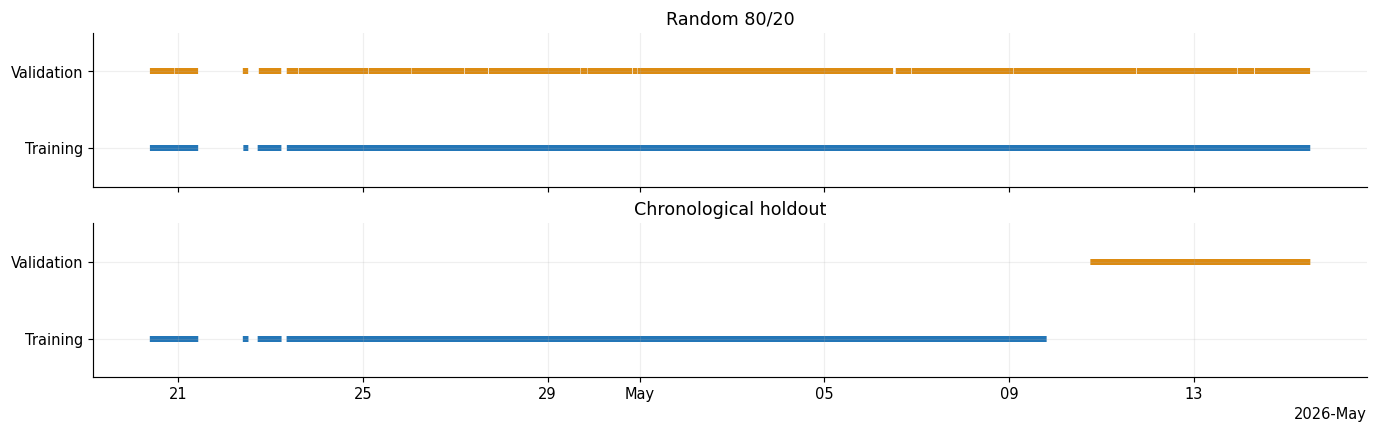

In [12]:
X = model_data[FEATURES]
y = model_data[TARGET]
positions = np.arange(len(model_data))
random_train, random_valid = train_test_split(positions, test_size=VALIDATION_FRACTION,
                                             random_state=SEED, shuffle=True)
cut = int(np.floor((1 - VALIDATION_FRACTION) * len(model_data)))
chrono_valid = positions[cut:]
chronological_start = model_data.index[cut]
chrono_train = positions[model_data.index < chronological_start - CHRONOLOGICAL_GAP]
splits = {'Random 80/20': (np.sort(random_train), np.sort(random_valid)),
          'Chronological holdout': (chrono_train, chrono_valid)}
split_rows = []
for name, (train, valid) in splits.items():
    assert len(train) > 100 and len(valid) > 20
    assert np.intersect1d(train, valid).size == 0
    split_rows.append({'Evaluation': name, 'Training bins': len(train), 'Validation bins': len(valid),
                       'Unused gap bins': len(model_data)-len(train)-len(valid),
                       'Training first': X.index[train].min(), 'Training last': X.index[train].max(),
                       'Validation first': X.index[valid].min(), 'Validation last': X.index[valid].max()})
assert X.index[chrono_train].max() < chronological_start - CHRONOLOGICAL_GAP
assert support.iloc[chrono_train].source_end.max() < support.iloc[chrono_valid].source_start.min(), 'Chronological smoothing support overlaps.'
print('Chronological train/validation raw support ranges are disjoint.')
display(pd.DataFrame(split_rows).set_index('Evaluation'))

fig, axes = plt.subplots(2, 1, figsize=(13, 4), sharex=True, layout='constrained')
for ax, (name, (train, valid)) in zip(axes, splits.items()):
    ax.scatter(X.index[train], np.zeros(len(train)), marker='|', s=18, label='Training', color='#2376b7')
    ax.scatter(X.index[valid], np.ones(len(valid)), marker='|', s=18, label='Validation', color='#dc8b12')
    ax.set(yticks=[0, 1], yticklabels=['Training', 'Validation'], title=name, ylim=(-0.5, 1.5))
date_axis(axes[-1])
plt.show()
plt.close(fig)


## 6. Train a basic Random Forest and evaluate it

Use 100 trees with the standard untuned scikit-learn settings (`max_depth=None`,
`min_samples_leaf=1`, `max_features=1.0`, bootstrap sampling). Fix only the random seed
and use two CPU workers. A training-mean predictor provides a simple reference using
exactly the same training/validation indices.

RMSE penalizes large errors more strongly than MAE. R² is measured against variation
in the validation observations and can be negative. Training scores are shown to expose
overfitting, not presented as evidence of generalization. The presentation's Sample 1
MLP scores are not acceptance thresholds for this different campaign and model.

In [13]:
def regression_metrics(observed, predicted):
    return {'RMSE (W/m²)': np.sqrt(mean_squared_error(observed, predicted)),
            'MAE (W/m²)': mean_absolute_error(observed, predicted),
            'R²': r2_score(observed, predicted),
            'Bias (prediction − measurement)': float(np.mean(np.asarray(predicted) - np.asarray(observed)))}

fitted_models, predictions, metric_rows = {}, {}, []
for name, (train, valid) in splits.items():
    pipeline = Pipeline([
        ('scale', MinMaxScaler()),
        ('forest', RandomForestRegressor(n_estimators=100, max_depth=None,
                                         min_samples_leaf=1, max_features=1.0,
                                         bootstrap=True, random_state=SEED, n_jobs=2)),
    ])
    pipeline.fit(X.iloc[train], y.iloc[train])
    predicted = pipeline.predict(X.iloc[valid])
    baseline = DummyRegressor(strategy='mean').fit(X.iloc[train], y.iloc[train])
    baseline_predicted = baseline.predict(X.iloc[valid])
    assert np.isfinite(predicted).all()
    scaler = pipeline.named_steps['scale']
    assert np.allclose(scaler.data_min_, X.iloc[train].min())
    assert np.allclose(scaler.data_max_, X.iloc[train].max())
    fitted_models[name] = pipeline
    predictions[name] = pd.DataFrame({'Measured': y.iloc[valid], 'Predicted': predicted,
                                      'Training-mean baseline': baseline_predicted}, index=y.iloc[valid].index)
    predictions[name]['Residual (prediction − measurement)'] = predicted - y.iloc[valid]
    for model_name, partition, observed, estimate in [
        ('Random Forest', 'Validation', y.iloc[valid], predicted),
        ('Training-mean baseline', 'Validation', y.iloc[valid], baseline_predicted),
        ('Random Forest', 'Training', y.iloc[train], pipeline.predict(X.iloc[train])),
    ]:
        metric_rows.append({'Evaluation': name, 'Model': model_name, 'Partition': partition,
                            'N': len(observed), **regression_metrics(observed, estimate)})

metrics = pd.DataFrame(metric_rows)
display(Markdown('**Held-out results (the actual performance estimates)**'))
display(metrics.loc[metrics.Partition.eq('Validation')].set_index(['Evaluation', 'Model']).drop(columns='Partition').round(4))
display(Markdown('**Training results (overfitting diagnostic only)**'))
display(metrics.loc[metrics.Partition.eq('Training')].set_index('Evaluation').drop(columns=['Model', 'Partition']).round(4))

**Held-out results (the actual performance estimates)**

N  RMSE (W/m²)  MAE (W/m²)  \
Evaluation            Model                                                   
Random 80/20          Random Forest           2261       7.9058      3.2062   
                      Training-mean baseline  2261      33.4250     26.9566   
Chronological holdout Random Forest           2261      18.6388     11.3442   
                      Training-mean baseline  2261      29.6503     25.6426   

                                                  R²  \
Evaluation            Model                            
Random 80/20          Random Forest           0.9440   
                      Training-mean baseline -0.0008   
Chronological holdout Random Forest           0.6043   
                      Training-mean baseline -0.0013   

                                              Bias (prediction − measurement)  
Evaluation            Model                                                    
Random 80/20          Random Forest                                    0.1920  
                      Training-mean baseline                           0.9286  
Chronological holdout Random Forest                                    3.8822  
                      Training-mean baseline                           1.0562

**Training results (overfitting diagnostic only)**

,N,RMSE (W/m²),MAE (W/m²),R²,Bias (prediction − measurement)
Evaluation,,,,,
Random 80/20,9043,2.8862,1.1587,0.9923,0.0069
Chronological holdout,8563,2.5892,0.9951,0.9943,0.0129


### Measured validation values versus predictions

Following the MATLAB `linearRegressionPlot` helper, show a least-squares fitted line
and its slope/intercept alongside the 1:1 agreement line. The displayed prediction
R² compares predictions directly with measurements; fit-line R² is a separate
descriptive correlation statistic and is not a replacement for prediction accuracy.
Both panels use held-out predictions only, including negative values and extremes.


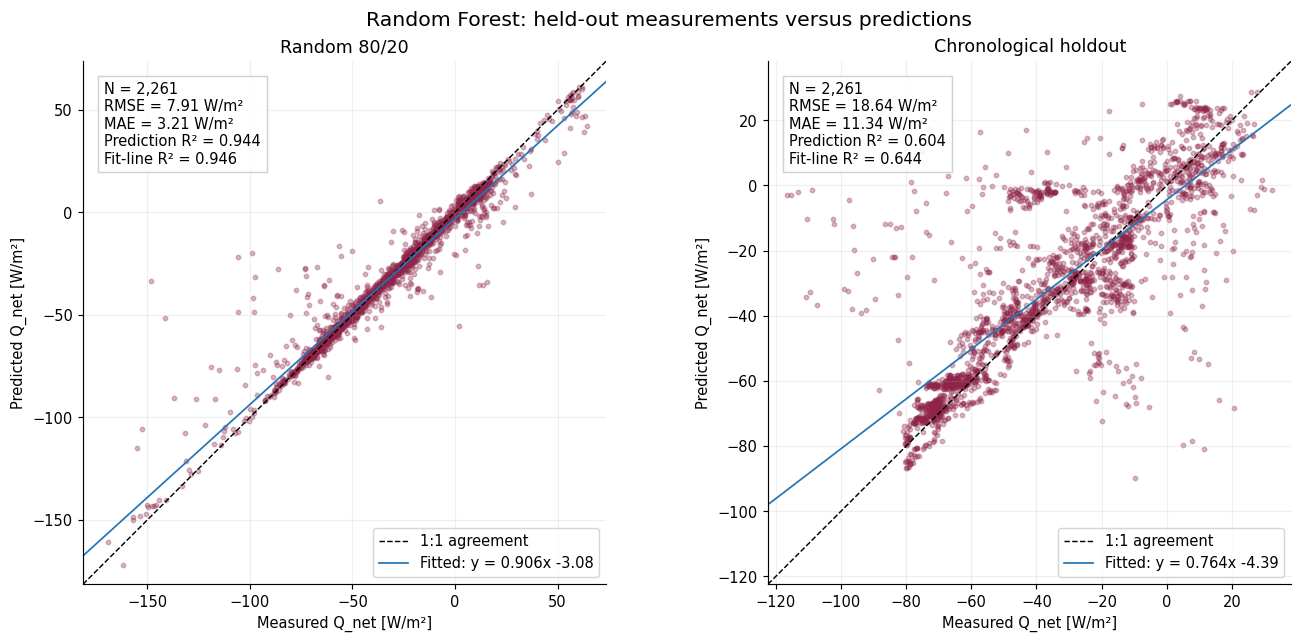

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), layout='constrained')
for ax, (name, result) in zip(axes, predictions.items()):
    ax.scatter(result['Measured'], result['Predicted'], s=9, alpha=0.32, color='#8e2548', rasterized=True)
    lower = result[['Measured', 'Predicted']].min().min()
    upper = result[['Measured', 'Predicted']].max().max()
    padding = 0.04 * max(upper-lower, 1)
    bounds = (lower-padding, upper+padding)
    ax.plot(bounds, bounds, '--', color='black', linewidth=1, label='1:1 agreement')
    slope, intercept = np.polyfit(result['Measured'], result['Predicted'], 1)
    line_x = np.asarray(bounds)
    ax.plot(line_x, slope*line_x+intercept, color='#2376b7', linewidth=1.2,
            label=f'Fitted: y = {slope:.3f}x {intercept:+.2f}')
    fit_r2 = r2_score(result['Predicted'], slope*result['Measured']+intercept)
    ax.set(xlim=bounds, ylim=bounds, xlabel='Measured Q_net [W/m²]',
           ylabel='Predicted Q_net [W/m²]', title=name)
    ax.set_aspect('equal', adjustable='box')
    values = regression_metrics(result['Measured'], result['Predicted'])
    annotation = (f"N = {len(result):,}\nRMSE = {values['RMSE (W/m²)']:.2f} W/m²\n"
                  f"MAE = {values['MAE (W/m²)']:.2f} W/m²\nPrediction R² = {values['R²']:.3f}\nFit-line R² = {fit_r2:.3f}")
    ax.text(0.04, 0.96, annotation, transform=ax.transAxes, va='top',
            bbox={'facecolor': 'white', 'alpha': 0.9, 'edgecolor': '#cccccc'})
    ax.legend(loc='lower right')
fig.suptitle('Random Forest: held-out measurements versus predictions', fontsize=14)
plt.show()
plt.close(fig)


## 7. Check errors and reliance on the inputs


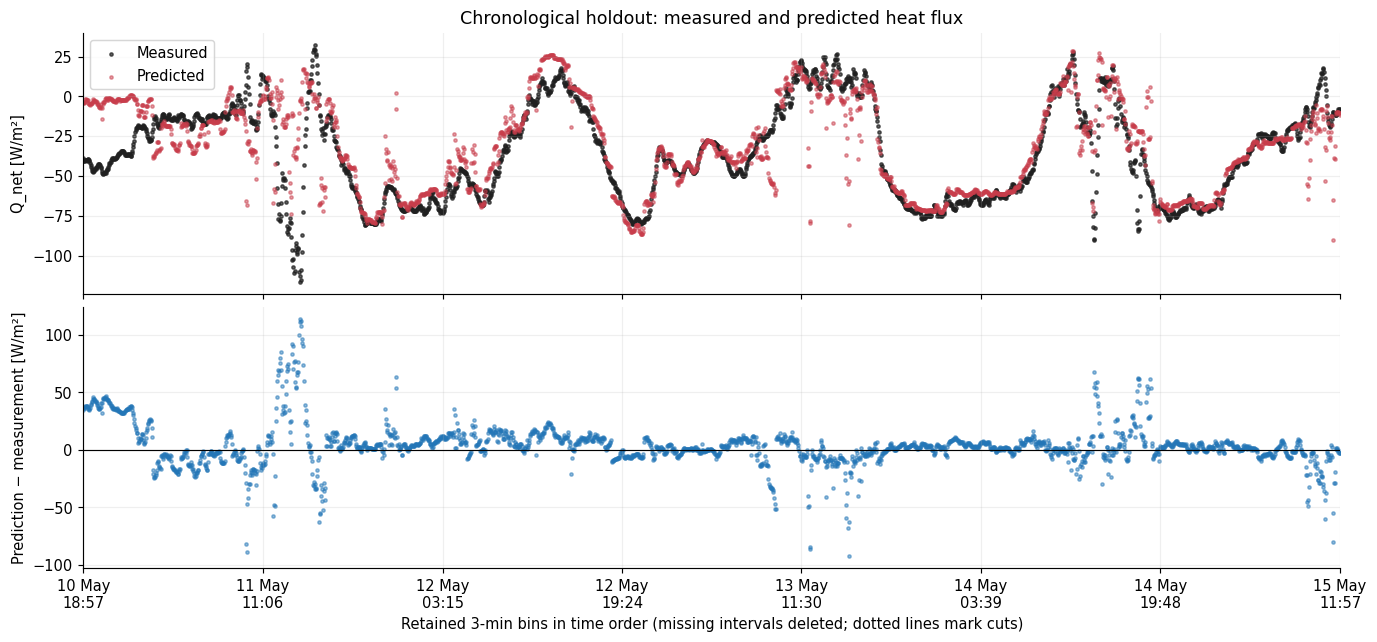

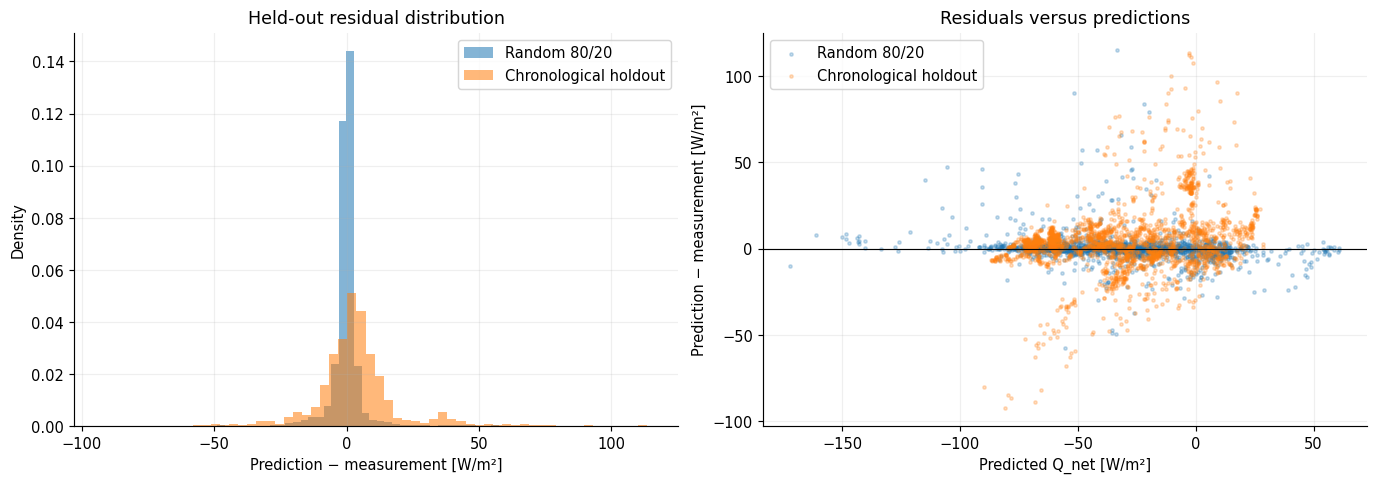

,RMSE increase (W/m²),Shuffle SD (W/m²)
Feature,,
v,0.7102,0.2314
T_amb,3.3823,0.1754
RH,5.5019,0.3537
T_sky,9.1489,0.3057
G,17.3731,0.2532


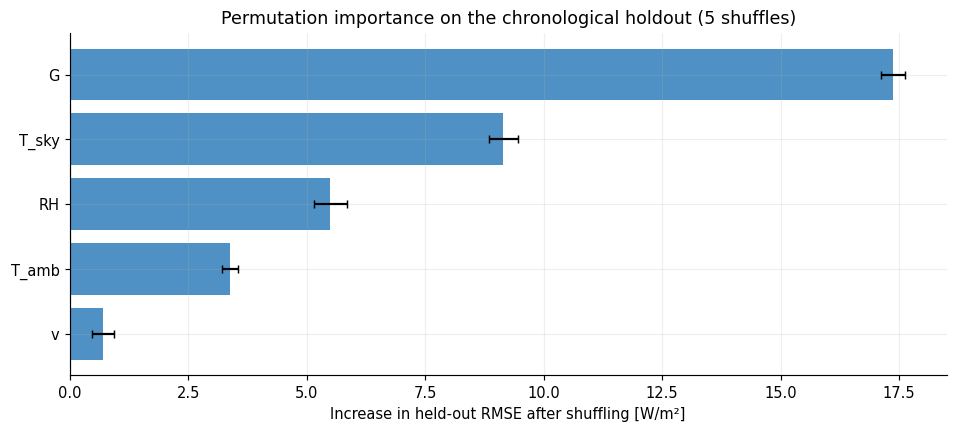

**Input-range shift in the later-period holdout**

,Train min,Train max,Validation min,Validation max,Validation outside training range (%)
T_amb,8.936,25.652,9.730,23.227,0.000
RH,18.200,95.000,21.867,95.650,0.840
v,0.192,3.749,0.270,8.630,1.858
G,0.000,1046.950,0.000,1046.200,0.000
T_sky,-50.000,20.728,-50.000,22.577,0.531


In [15]:
later = predictions['Chronological holdout'].sort_index()
later_x = np.arange(len(later))
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, layout='constrained')
for ax in axes:
    mark_cuts(ax, later.index)
axes[0].scatter(later_x, later['Measured'], s=5, alpha=0.7, color='#202020', label='Measured')
axes[0].scatter(later_x, later['Predicted'], s=5, alpha=0.5, color='#c83d4b', label='Predicted')
axes[0].set(ylabel=LABELS[TARGET][1], title='Chronological holdout: measured and predicted heat flux')
axes[0].legend()
axes[1].scatter(later_x, later['Residual (prediction − measurement)'], s=5, alpha=0.5, color='#2376b7')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_ylabel('Prediction − measurement [W/m²]')
gapless_axis(axes[1], later.index)
axes[1].set_xlabel(GAPLESS_XLABEL)
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained')
for name, result in predictions.items():
    residuals = result['Residual (prediction − measurement)']
    axes[0].hist(residuals, bins=60, alpha=0.55, density=True, label=name)
    axes[1].scatter(result['Predicted'], residuals, s=5, alpha=0.25, label=name)
axes[0].set(xlabel='Prediction − measurement [W/m²]', ylabel='Density', title='Held-out residual distribution')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set(xlabel='Predicted Q_net [W/m²]', ylabel='Prediction − measurement [W/m²]', title='Residuals versus predictions')
axes[0].legend()
axes[1].legend()
plt.show()
plt.close(fig)

train, valid = splits['Chronological holdout']
importance = permutation_importance(fitted_models['Chronological holdout'], X.iloc[valid], y.iloc[valid],
                                    scoring='neg_root_mean_squared_error', n_repeats=5,
                                    random_state=SEED, n_jobs=1)
importance_table = pd.DataFrame({'Feature': FEATURES, 'RMSE increase (W/m²)': importance.importances_mean,
                                 'Shuffle SD (W/m²)': importance.importances_std}).sort_values('RMSE increase (W/m²)')
display(importance_table.set_index('Feature').round(4))
fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
ax.barh(importance_table.Feature, importance_table['RMSE increase (W/m²)'],
        xerr=importance_table['Shuffle SD (W/m²)'], color='#2376b7', alpha=0.8, capsize=3)
ax.axvline(0, color='black', linewidth=0.7)
ax.set(xlabel='Increase in held-out RMSE after shuffling [W/m²]',
       title='Permutation importance on the chronological holdout (5 shuffles)')
plt.show()
plt.close(fig)

range_check = pd.DataFrame({'Train min': X.iloc[train].min(), 'Train max': X.iloc[train].max(),
                            'Validation min': X.iloc[valid].min(), 'Validation max': X.iloc[valid].max()})
range_check['Validation outside training range (%)'] = 100 * (
    X.iloc[valid].lt(X.iloc[train].min()) | X.iloc[valid].gt(X.iloc[train].max())).mean()
display(Markdown('**Input-range shift in the later-period holdout**'))
display(range_check.round(3))

## 8. Results, interpretation and reusable prediction function

In [16]:
validation_metrics = metrics.loc[metrics.Partition.eq('Validation')].set_index(['Evaluation', 'Model'])
summary_lines = [f'### Executed baseline result: {DATA_SCOPE}',
                 f'- Retained **{len(model_data):,}** processed {GRID} bins from '
                 f'**{model_data.index.min():%d %b %Y}** to **{model_data.index.max():%d %b %Y}**.',
                 f'- Excluded **{len(rejected):,}** incomplete grid intervals. **Zero values were interpolated.**']
for name in splits:
    forest_result = validation_metrics.loc[(name, 'Random Forest')]
    baseline_result = validation_metrics.loc[(name, 'Training-mean baseline')]
    improvement = 100 * (1 - forest_result['RMSE (W/m²)'] / baseline_result['RMSE (W/m²)'])
    summary_lines.append(f"- **{name}:** RMSE **{forest_result['RMSE (W/m²)']:.2f} W/m²**, "
                         f"MAE **{forest_result['MAE (W/m²)']:.2f} W/m²**, R² **{forest_result['R²']:.3f}**. "
                         f"RMSE change versus the training-mean baseline: **{improvement:.1f}% reduction** "
                         '(a negative reduction means worse performance).')
random_score = validation_metrics.loc[('Random 80/20', 'Random Forest'), 'R²']
later_score = validation_metrics.loc[('Chronological holdout', 'Random Forest'), 'R²']
if later_score < random_score:
    summary_lines.append('- Later-period performance is weaker than random-split performance; '
                         'use the chronological result when discussing prediction at later dates.')
if later_score < 0:
    summary_lines.append('- Chronological R² is negative: the model has not demonstrated useful '
                         'later-period generalization on this split.')
if DATA_SCOPE == 'full_campaign':
    summary_lines.append('- Full-campaign results remain conditional on the earlier merge; native '
                         'instrument alignment after 15 May cannot be independently audited with these files.')
summary_lines.append('- The target is the 20-sample-smoothed, three-minute mean recorded flux. Random validation shares smoothing support; chronological support is disjoint.')
summary_lines.append('- Verify the inherited heat-flux calibration/sign and investigate sensor-floor '
                     'values and extreme residuals before claiming physical cooling performance.')
display(Markdown('\n'.join(summary_lines)))

final_model = Pipeline([
    ('scale', MinMaxScaler()),
    ('forest', RandomForestRegressor(n_estimators=100, max_depth=None, min_samples_leaf=1,
                                     max_features=1.0, bootstrap=True, random_state=SEED, n_jobs=2)),
]).fit(X, y)

def predict_net_heat_flux(atmospheric_means):
    """Predict recorded-sign W/m² from a DataFrame of the five bin-mean inputs."""
    if not isinstance(atmospheric_means, pd.DataFrame):
        raise TypeError('Pass a pandas DataFrame with the five named atmospheric inputs.')
    values = atmospheric_means.loc[:, FEATURES].apply(pd.to_numeric, errors='raise')
    if values.empty or not np.isfinite(values.to_numpy()).all():
        raise ValueError('Provide at least one row of finite, non-missing input values.')
    outside = values.lt(X.min()) | values.gt(X.max())
    return pd.DataFrame({'Predicted Q_net (W/m²)': final_model.predict(values),
                         'Outside fitted input range': outside.any(axis=1)}, index=values.index)

display(Markdown('**Function demonstration on three existing input rows (not a new validation score):**'))
display(predict_net_heat_flux(X.tail(3)))


### Executed baseline result: native_exports
- Retained **11,304** processed 3min bins from **20 Apr 2026** to **15 May 2026**.
- Excluded **743** incomplete grid intervals. **Zero values were interpolated.**
- **Random 80/20:** RMSE **7.91 W/m²**, MAE **3.21 W/m²**, R² **0.944**. RMSE change versus the training-mean baseline: **76.3% reduction** (a negative reduction means worse performance).
- **Chronological holdout:** RMSE **18.64 W/m²**, MAE **11.34 W/m²**, R² **0.604**. RMSE change versus the training-mean baseline: **37.1% reduction** (a negative reduction means worse performance).
- Later-period performance is weaker than random-split performance; use the chronological result when discussing prediction at later dates.
- The target is the 20-sample-smoothed, three-minute mean recorded flux. Random validation shares smoothing support; chronological support is disjoint.
- Verify the inherited heat-flux calibration/sign and investigate sensor-floor values and extreme residuals before claiming physical cooling performance.

**Function demonstration on three existing input rows (not a new validation score):**

,Predicted Q_net (W/m²),Outside fitted input range
timestamp,,
2026-05-15 11:51:00,-8.1439,False
2026-05-15 11:54:00,-8.3864,False
2026-05-15 11:57:00,-8.6307,False


## 9. Export the final dataset and verify traceability

`processed/final_processed_dataset.csv` contains exactly the physical-unit model
table, with timestamp, Q_net, T_amb, RH, G, v and T_sky. It opens in Excel and is
read back below to verify numerical equivalence. Missing intervals are absent,
so retained timestamps can be more than three minutes apart.

`results/bin_audit.csv` records eligibility, native counts, unsmoothed values,
per-variable smoothing support and the common interval end. Companion files record
split membership, held-out predictions, metrics, native gaps and processing metadata.
These supply the chain from input hashes to final data and validation.


In [ ]:
assert model_data.equals(aligned.loc[aligned[MODEL_COLS].notna().all(axis=1), MODEL_COLS])
assert model_data.index.intersection(rejected).empty
assert (counts.loc[model_data.index, MODEL_COLS] >= 1).all().all()
assert list(X.columns) == FEATURES and TARGET not in X.columns
for name, (train, valid) in splits.items():
    result = predictions[name]
    assert result.index.equals(y.iloc[valid].index)
    assert np.allclose(result.Measured, y.iloc[valid])
    independent_rmse = np.sqrt(np.mean((result.Predicted-result.Measured)**2))
    assert np.isclose(independent_rmse, validation_metrics.loc[(name, 'Random Forest'), 'RMSE (W/m²)'])
    assert fitted_models[name].named_steps['scale'].n_samples_seen_ == len(train)
for name, filename in source_names.items():
    assert hashlib.sha256((DATA_DIR / filename).read_bytes()).hexdigest() == source_inventory.loc[name, 'SHA256']

output_columns = [TARGET, 'T_amb', 'RH', 'G', 'v', 'T_sky']
export_table = model_data[output_columns].rename_axis('timestamp')
results_dir = PROJECT_ROOT / 'results'
results_dir.mkdir(exist_ok=True)
final_path = DATA_DIR / 'final_processed_dataset.csv'
export_table.to_csv(final_path, float_format='%.12g', date_format='%Y-%m-%d %H:%M:%S')
roundtrip = pd.read_csv(final_path, parse_dates=['timestamp']).set_index('timestamp')
pd.testing.assert_index_equal(roundtrip.index, export_table.index)
np.testing.assert_allclose(roundtrip, export_table, rtol=1e-10, atol=1e-10)

audit = pd.DataFrame({'interval_end': aligned.index + pd.Timedelta(GRID),
                      'retained': complete}, index=aligned.index)
audit.index.name = 'timestamp'
for name in MODEL_COLS:
    audit[name + '_native_count'] = counts[name]
    audit[name + '_unsmoothed_mean'] = raw_aligned[name]
    audit[name + '_support_start'] = support_starts[name]
    audit[name + '_support_end'] = support_ends[name]
audit['missing_variables'] = raw_aligned.isna().apply(lambda row: ','.join(row.index[row]), axis=1)
audit.to_csv(results_dir / 'bin_audit.csv', float_format='%.12g')
split_export = support.copy()
for name, (train, valid) in splits.items():
    split_export[name] = 'excluded_gap'
    split_export.loc[X.index[train], name] = 'train'
    split_export.loc[X.index[valid], name] = 'validation'
split_export.to_csv(results_dir / 'split_assignments.csv', index_label='timestamp')
prediction_export = pd.concat(predictions, names=['evaluation', 'timestamp'])
prediction_export.to_csv(results_dir / 'validation_predictions.csv', float_format='%.12g')
metrics.to_csv(results_dir / 'metrics.csv', index=False, float_format='%.12g')
native_gaps.to_csv(results_dir / 'native_gaps.csv', index=False)
reference = PROJECT_ROOT / 'references/PLOT_TRESCO_CORRELATIONS_ML-2.m'
metadata = {
    'scope': DATA_SCOPE, 'grid': GRID, 'moving_average_samples': MOVING_WINDOW,
    'moving_average': 'Centered: 10 previous, current, 9 following; shrink within uninterrupted valid segments',
    'max_native_gap': str(MAX_SOURCE_GAP), 'interpolation': False,
    'source_units': {'Q_net':'W/m^2 (recorded sign)', 'T_amb':'deg C', 'RH':'%', 'G':'W/m^2', 'v':'m/s', 'T_sky':'deg C'},
    'rows': len(model_data), 'grid_slots': len(aligned), 'excluded_bins': len(rejected),
    'first_timestamp': str(model_data.index.min()), 'last_timestamp': str(model_data.index.max()),
    'common_acquisition_start': str(overlap_start), 'common_acquisition_end': str(overlap_end),
    'seed': SEED, 'validation_fraction': VALIDATION_FRACTION,
    'chronological_gap': str(CHRONOLOGICAL_GAP),
    'chronological_source_support_disjoint': bool(support.iloc[chrono_train].source_end.max() < support.iloc[chrono_valid].source_start.min()),
    'random_split_support_overlap': 'Expected; shuffled score is reconstruction only',
    'source_hashes': source_inventory.SHA256.to_dict(),
    'matlab_sha256': hashlib.sha256(reference.read_bytes()).hexdigest(),
    'versions': versions.to_dict(),
    'artifacts': {}
}
for artifact in [final_path, *sorted(results_dir.glob('*.csv'))]:
    metadata['artifacts'][artifact.relative_to(PROJECT_ROOT).as_posix()] = hashlib.sha256(artifact.read_bytes()).hexdigest()
(results_dir / 'processing_metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')

print('disjoint chronological source support, training-only scaling, held-out metrics and CSV round trip.')
print(f'Exported {len(export_table):,} rows to processed/final_processed_dataset.csv.')



Passed: unchanged inputs, MATLAB window examples, gap isolation, complete bins,
disjoint chronological source support, training-only scaling, held-out metrics and CSV round trip.
Exported 11,304 rows to processed/final_processed_dataset.csv.
All 20 figures are embedded in main.ipynb; no separate figure files were written.
